In [1]:
import pickle as pkl
import numpy as np
np.random.seed(0)
import matplotlib.pyplot as plt
import seaborn as sns 
# import tensorflow as tf
import matplotlib.pyplot as plt
%matplotlib inline
import math
from timescale_utils import *
dir_name = 'heterogeneity_results_MG'

# file_name_ddn = '2024-09-26_single_task_exp_DDN_fixed_decay_per_cluster.p'
# file_name_esn = '2024-09-26_single_task_exp_BL_fixed_decay_per_cluster.p'

# esn_dict = pkl.load(open(dir_name + '/' + file_name_esn, 'rb'))
# ddn_dict = pkl.load(open(dir_name + '/' + file_name_ddn, 'rb'))

file_name_esn_dist_net    = '2025-04-29_BL_dist_decay_net_wide.p'
file_name_esn_dist_clust  = '2025-04-24_BL_dist_decay_per_cluster.p'
file_name_esn_fixed_clust = '2025-04-24_BL_fixed_decay_per_cluster.p' 
file_name_esn_fixed_net   = '2025-04-24_BL_fixed_decay_net_wide.p'

file_name_ddn_fixed_net   = '2025-04-24_DDN_fixed_decay_net_wide.p'
file_name_ddn_fixed_clust = '2025-04-24_DDN_fixed_decay_per_cluster.p'
file_name_ddn_dist_net    = '2025-04-24_DDN_dist_decay_net_wide.p'
file_name_ddn_dist_clust  = '2025-04-24_DDN_dist_decay_per_cluster.p'

 


esn_dist_net_dict    =  pkl.load(open(dir_name + '/' + file_name_esn_dist_net,    'rb'))
esn_dist_clust_dict  =  pkl.load(open(dir_name + '/' + file_name_esn_dist_clust,  'rb'))
esn_fixed_net_dict   =  pkl.load(open(dir_name + '/' + file_name_esn_fixed_net,   'rb'))
esn_fixed_clust_dict =  pkl.load(open(dir_name + '/' + file_name_esn_fixed_clust, 'rb'))

ddn_fixed_net_dict   =  pkl.load(open(dir_name + '/' + file_name_ddn_fixed_net,   'rb'))
ddn_fixed_clust_dict =  pkl.load(open(dir_name + '/' + file_name_ddn_fixed_clust, 'rb'))
ddn_dist_net_dict    =  pkl.load(open(dir_name + '/' + file_name_ddn_dist_net,    'rb'))
ddn_dist_clust_dict  =  pkl.load(open(dir_name + '/' + file_name_ddn_dist_clust,  'rb'))



# from tensorflow.python.ops import parallel_for as pfor

import pdb

from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D
# import tf_utils


In [2]:
import sys
sys.path.append('C:/Users/Nishant Joshi/Downloads/DDN-public/fixed-point-finder')

In [3]:
# esn_example = esn_dict['example net']
# ddn_example = ddn_dict['example net']




ESN_dist_decay_net_wide_example                   = esn_dist_net_dict['example net'] 
ESN_dist_decay_per_cluster_example                = esn_dist_clust_dict['example net'] 
ESN_fixed_decay_net_wide_example                  = esn_fixed_net_dict['example net'] 
ESN_fixed_decay_per_cluster_example               = esn_fixed_clust_dict['example net'] 

DDN_dist_decay_net_wide_example                   = ddn_fixed_net_dict['example net'] 
DDN_fixed_decay_net_wide_example                  = ddn_fixed_clust_dict['example net'] 
DDN_dist_decay_per_cluster_example                = ddn_dist_net_dict['example net'] #
DDN_fixed_decay_per_cluster_example               = ddn_dist_clust_dict['example net'] 

# DDN_dist_decay_net_wide_fixed_delays_example      = DDN_dist_decay_net_wide_fixed_delays_dict['example net'] 
# DDN_dist_decay_per_cluster_fixed_delays_example   = DDN_dist_decay_per_cluster_fixed_delays_dict['example net'] 
# DDN_fixed_decay_per_cluster_fixed_delays_example  = DDN_fixed_decay_per_cluster_fixed_delays_dict['example net'] 
# DDN_fixed_decay_net_wide_fixed_delays_example     = DDN_fixed_decay_net_wide_fixed_delays_dict['example net']

In [4]:
from utils import eval_candidate_signal_gen_horizon
from utils import *
def get_validation_throughout_evolution(dict, gen_max, populations=False):
    # Validation scores are saved in a matrix with dimensions:
    # generations x hyperparameter candidates x re-initializations
    all_scores = dict['validation performance'][:gen_max, :, :]

    # from the re-initializations from the same hyperparameter set/candidate, we take the average
    best_candidate_scores = np.mean(all_scores, axis=-1)

    # from the population of hyperparameter candidates, we select the best candidate
    best_gen_scores = np.max(best_candidate_scores, axis=-1)
    return best_gen_scores

def resample_net_MG_best(data_dict):
    best_params = data_dict['evolutionary strategy'].best.x
    net = data_dict['example net']
    best_net = net.get_new_network_from_serialized(best_params)
    return best_net

def get_best_candidate(dict, gen_max, multitask=False):
    best_gen_scores = get_validation_throughout_evolution(dict, gen_max, )   
    best_candidates = get_validation_throughout_evolution(dict, gen_max, populations=True, )
    best_gen_ind = np.argmin(best_gen_scores)
    best_candidate_ind = np.argmin(best_candidates[best_gen_ind])
    return best_gen_ind, best_candidate_ind
    
def sample_best_net(dict, n, gen_max, multitask=False):
    gen, ind = get_best_candidate(dict, gen_max, multitask=multitask)
    print(gen, ind)
    start_net = dict['example net']
    best_parameter_set = dict['parameters'][gen, ind, :]
    best_nets = []
    for i in range(n):
        best_net = start_net.get_new_network_from_serialized(best_parameter_set)
        best_nets.append(best_net)
    return best_nets

def retrain_net_MG(best_net, data_dict, tau):
    best_net.reset_network()
    x0_range = data_dict['start value range']
    n_seq = data_dict['number of sequences']
    n_sam = data_dict['number of samples']
    tau_range = [tau, tau]
    error_margin = data_dict['error margin']
    alphas = data_dict['alpha grid']
    val, model, net = eval_candidate_signal_gen_horizon(best_net,
                                                          n_seq['unsupervised'],
                                                          n_seq['supervised'],
                                                          0,
                                                          n_sam['unsupervised'],
                                                          n_sam['supervised'],
                                                          0,
                                                          error_margin=error_margin,
                                                          alphas=alphas,
                                                          tau_range=tau_range,
                                                          x0_range=x0_range,
                                                          n_range=[10, 10]
                                                         )
    return val, model, net

def test_net_MG(network, model, error_margin, test_data):
    warmup = 400
    prediction_steps_across_sequences = []
    y_across_sequences = []
    max_it_val = 500
    sim = NetworkSimulator(network)

    for sequence in test_data:
        start_input_val = sequence[warmup]
        labels_val = sequence[warmup + 1:]
        sim.warmup(sequence[:warmup])
        error = 0
        j = 0
        feedback_in = start_input_val
        label_variance = np.var(labels_val)
        steps = 0
        y = []
        while j <= max_it_val:
            feedback_in = np.ones((len(network.neurons_in),)) * feedback_in
            network.update_step(feedback_in)
            output = network.A[network.neurons_out, 0].T
            if len(output.shape) == 1:
                output = np.expand_dims(output, 0)
            feedback_in = model.predict(output)[0][0]
            y.append(feedback_in)
            error = single_sample_NRSE(feedback_in, labels_val[j, 0],
                                       label_variance)
            j += 1
            if error <= error_margin:
                steps += 1

        prediction_steps_across_sequences.append(steps)
        y_across_sequences.append(y)
    return y_across_sequences, prediction_steps_across_sequences


## Plot Validation scores for all networks

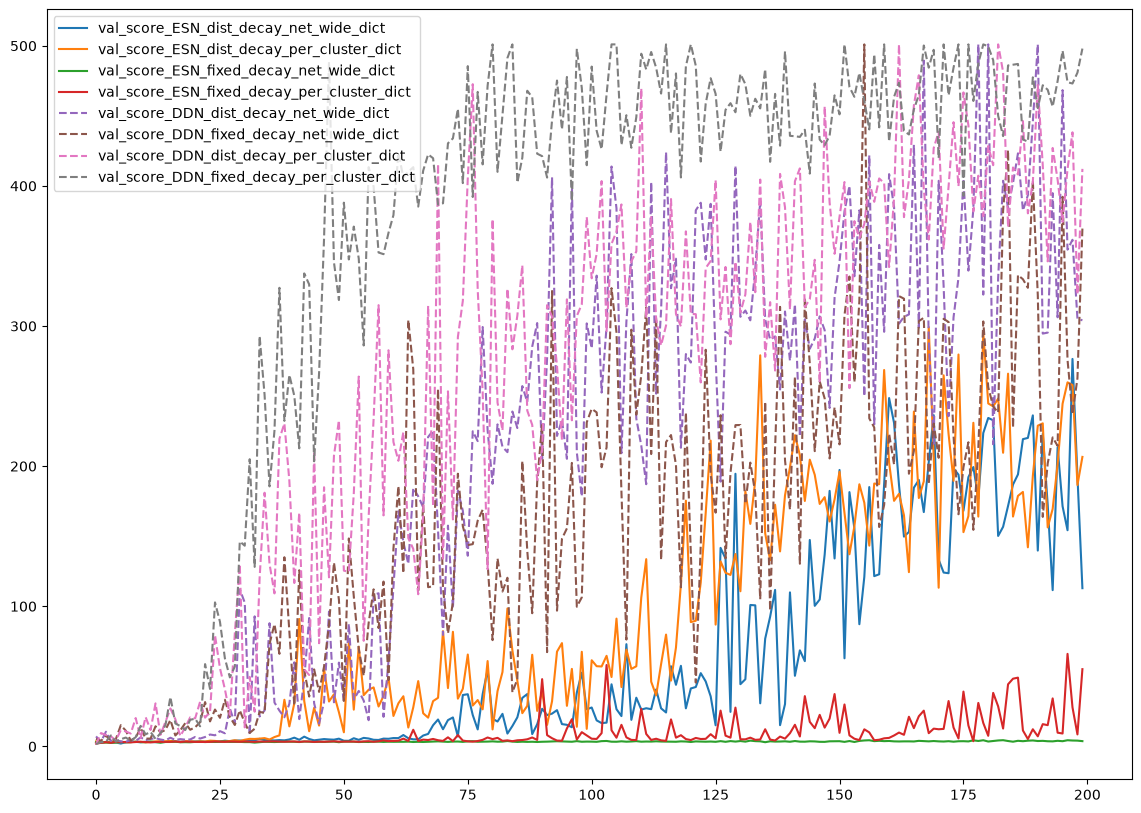

In [5]:
def get_validation_throughout_evolution(dict, gen_max, populations=False):
    # Validation scores are saved in a matrix with dimensions:
    # generations x hyperparameter candidates x re-initializations
    all_scores = dict['validation performance'][:gen_max, :, :]

    # from the re-initializations from the same hyperparameter set/candidate, we take the average
    best_candidate_scores = np.mean(all_scores, axis=-1)

    # from the population of hyperparameter candidates, we select the best candidate
    best_gen_scores = np.max(best_candidate_scores, axis=-1)
    return best_gen_scores

gen_max = 200
# val_scores_ddn = get_validation_throughout_evolution(ddn_dict, gen_max, multitask=False)
# val_scores_esn = get_validation_throughout_evolution(esn_dict, gen_max, multitask=False)

val_score_ESN_dist_decay_net_wide_dict                 =  get_validation_throughout_evolution(esn_dist_net_dict, gen_max=gen_max)
val_score_ESN_dist_decay_per_cluster_dict              =  get_validation_throughout_evolution(esn_dist_clust_dict, gen_max=gen_max)
val_score_ESN_fixed_decay_net_wide_dict                =  get_validation_throughout_evolution(esn_fixed_net_dict, gen_max=gen_max)
val_score_ESN_fixed_decay_per_cluster_dict             =  get_validation_throughout_evolution(esn_fixed_clust_dict, gen_max=gen_max)

val_score_DDN_dist_decay_net_wide_dict                 =  get_validation_throughout_evolution(ddn_fixed_net_dict, gen_max=gen_max)
val_score_DDN_fixed_decay_net_wide_dict                =  get_validation_throughout_evolution(ddn_fixed_clust_dict, gen_max=gen_max)
val_score_DDN_dist_decay_per_cluster_dict              =  get_validation_throughout_evolution(ddn_dist_net_dict, gen_max=gen_max) #
val_score_DDN_fixed_decay_per_cluster_dict             =  get_validation_throughout_evolution(ddn_dist_clust_dict, gen_max=gen_max)

# val_score_DDN_dist_decay_net_wide_fixed_delays_dict    =  get_validation_throughout_evolution(DDN_dist_decay_net_wide_fixed_delays_dict, gen_max=gen_max, multitask=False)
# val_score_DDN_dist_decay_per_cluster_fixed_delays_dict =  get_validation_throughout_evolution(DDN_dist_decay_per_cluster_fixed_delays_dict, gen_max=gen_max, multitask=False)
# val_score_DDN_fixed_decay_per_cluster_fixed_delays_dict=  get_validation_throughout_evolution(DDN_fixed_decay_per_cluster_fixed_delays_dict, gen_max=gen_max, multitask=False)
# val_score_DDN_fixed_decay_net_wide_fixed_delays_dict   =  get_validation_throughout_evolution(DDN_fixed_decay_net_wide_fixed_delays_dict, gen_max=gen_max, multitask=False)

fig = plt.figure(figsize= [14,10])

plt.plot(val_score_ESN_dist_decay_net_wide_dict,                   linestyle='-',  label = 'val_score_ESN_dist_decay_net_wide_dict')
plt.plot(val_score_ESN_dist_decay_per_cluster_dict,                linestyle='-',  label = 'val_score_ESN_dist_decay_per_cluster_dict')
plt.plot(val_score_ESN_fixed_decay_net_wide_dict,                  linestyle='-',  label = 'val_score_ESN_fixed_decay_net_wide_dict')
plt.plot(val_score_ESN_fixed_decay_per_cluster_dict,               linestyle='-',  label = 'val_score_ESN_fixed_decay_per_cluster_dict')
plt.plot(val_score_DDN_dist_decay_net_wide_dict,                   linestyle='--', label = 'val_score_DDN_dist_decay_net_wide_dict' )
plt.plot(val_score_DDN_fixed_decay_net_wide_dict,                  linestyle='--', label = 'val_score_DDN_fixed_decay_net_wide_dict' )
plt.plot(val_score_DDN_dist_decay_per_cluster_dict,                linestyle='--', label = 'val_score_DDN_dist_decay_per_cluster_dict' )
plt.plot(val_score_DDN_fixed_decay_per_cluster_dict,               linestyle='--', label = 'val_score_DDN_fixed_decay_per_cluster_dict' )

# plt.plot(val_score_DDN_dist_decay_net_wide_fixed_delays_dict,      linestyle=':',  label ='val_score_DDN_dist_decay_net_wide_fixed_delays_dict' )
# plt.plot(val_score_DDN_dist_decay_per_cluster_fixed_delays_dict,   linestyle=':',  label ='val_score_DDN_dist_decay_per_cluster_fixed_delays_dict' )
# plt.plot(val_score_DDN_fixed_decay_per_cluster_fixed_delays_dict,  linestyle=':',  label ='val_score_DDN_fixed_decay_per_cluster_fixed_delays_dict' )
# plt.plot(val_score_DDN_fixed_decay_net_wide_fixed_delays_dict,     linestyle=':',  label ='val_score_DDN_fixed_decay_net_wide_fixed_delays_dict' )

plt.legend()
plt.savefig('G:/My Drive/Data For Publication/paper3/figs_MG/val_scores_MG.pdf', dpi=300, bbox_inches='tight')
plt.show()

## Select Best nets

In [6]:
nr_of_nets = 200
gen_max = 10

best_nets_ESN_dist_decay_net_wide_dict           = resample_net_MG_best(esn_dist_net_dict)
best_nets_ESN_dist_decay_per_cluster_dict        = resample_net_MG_best(esn_dist_clust_dict)
best_nets_ESN_fixed_decay_net_wide_dict          = resample_net_MG_best(esn_fixed_net_dict)
best_nets_ESN_fixed_decay_per_cluster_dict       = resample_net_MG_best(esn_fixed_clust_dict)

best_nets_DDN_dist_decay_net_wide_dict           = resample_net_MG_best(ddn_fixed_net_dict)
best_nets_DDN_fixed_decay_net_wide_dict          = resample_net_MG_best(ddn_fixed_clust_dict)
best_nets_DDN_dist_decay_per_cluster_dict        = resample_net_MG_best(ddn_dist_net_dict)
best_nets_DDN_fixed_decay_per_cluster_dict       = resample_net_MG_best(ddn_dist_clust_dict)

# best_nets_DDN_dist_decay_net_wide_fixed_delays_dict      = sample_best_net(DDN_dist_decay_net_wide_fixed_delays_dict,     nr_of_nets, gen_max, multitask=False)
# best_nets_DDN_dist_decay_per_cluster_fixed_delays_dict   = sample_best_net(DDN_dist_decay_per_cluster_fixed_delays_dict,  nr_of_nets, gen_max, multitask=False)
# best_nets_DDN_fixed_decay_per_cluster_fixed_delays_dict  = sample_best_net(DDN_fixed_decay_per_cluster_fixed_delays_dict, nr_of_nets, gen_max, multitask=False)
# best_nets_DDN_fixed_decay_net_wide_fixed_delays_dict     = sample_best_net(DDN_fixed_decay_net_wide_fixed_delays_dict,    nr_of_nets, gen_max, multitask=False)

## ESN Dist decay net wide

In [7]:
from reservoirpy.datasets import mackey_glass
net = best_nets_ESN_dist_decay_net_wide_dict
warmup  = 1000

narma_input = mackey_glass(5000, seed=0)
INPUT = narma_input.T
sim = NetworkSimulator(net)
sim.warmup(narma_input[:warmup])

### Find fixed point

In [8]:
state,info = settle_to_fixed_point(net, input_constant=[0.0], max_steps=10000, tol=1e-9, consecutive_required=200, verbose=True)
x_star = state[net.neurons_out,0]

Step 1: update error = 8.396e-01, consecutive = 0
Converged to fixed point after 867 steps (consecutive = 200).


### Calculate jacobian

In [9]:
alpha = net.decay[net.neurons_out]
# W_by_delay = net.W_masked_list
active = np.asarray(alpha) > 0 # indices of active units
alpha_a = np.asarray(alpha)[active] # decay rates of active units
# x_a = x_star[active] # states of active units
# W_a = [Wd[np.ix_(active, active)] for Wd in W_by_delay] # weight matrices for active units

J_esn, g_a = esn_jacobian(net, x_star,  active_only=True,activation='sigmoid') 
mu_a = np.linalg.eigvals(J_esn)
r_a = np.abs(mu_a)
print("spectral radius (active units):", r_a.max())

spectral radius (active units): 0.9756165773564508


In [ ]:
dir_name = 'timescale_factors_MG/'
save_spectrum(mu_a, 'MG', 'ESN','dist','net_wide', dir_name)

In [11]:
mu = np.linalg.eigvals(J_esn)          # one matrix only
r = np.abs(mu)

print("rho:", r.max(), " -> tau_max:", -net.dt/np.log(r.max()))
print("top 10 |mu|:", np.sort(r)[-10:])

meaningful = (r > 1e-6) & (r < 1 - 1e-12) # indices of meaningful eigenvalues
tau = -net.dt/np.log(r[meaningful]) # time constants for meaningful eigenvalues
print("n meaningful:", meaningful.sum())
print("tau sorted (top 15):", np.sort(tau)[-15:])
print("tau quantiles:", np.quantile(tau, [0.1, 0.5, 0.9, 0.99]))

rho: 0.9756165773564508  -> tau_max: 3819.264049653479
top 10 |mu|: [0.91563247 0.91792378 0.94162627 0.95016211 0.95760432 0.95956582
 0.96153101 0.96622465 0.97229564 0.97561658]
n meaningful: 62
tau sorted (top 15): [ 567.9536166   575.38943968  649.92801641  848.21907377  988.71424014
 1069.66932198 1100.886162   1567.51250251 1844.20950809 2176.35203682
 2284.24847238 2403.38003526 2744.00095608 3355.7455506  3819.26404965]
tau quantiles: [  95.19108058  195.87619005 1816.53980753 3536.51776523]


In [12]:
timescale_dict = timescales_from_eigenvalues(net,J_esn, zero_tol=1e-12)

rho: 0.9756165773564508  -> tau_max: 3819.264049653479
top 10 |mu|: [0.91563247 0.91792378 0.94162627 0.95016211 0.95760432 0.95956582
 0.96153101 0.96622465 0.97229564 0.97561658]


### Plot spectral radius

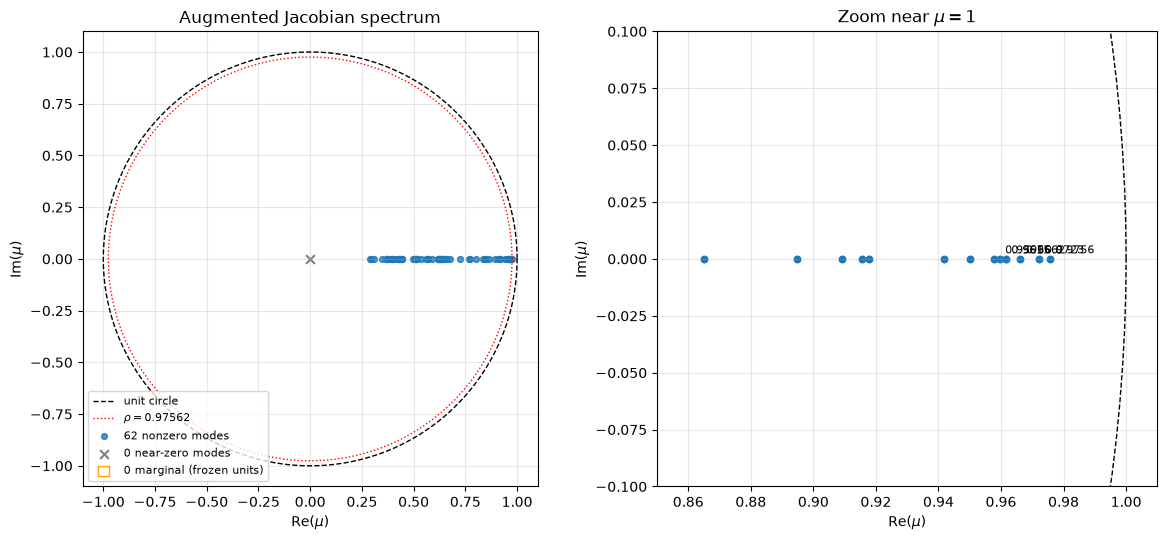

In [13]:

fig = plot_spectrum(mu, mu_full=mu)
# fig.savefig("spectrum.png", dpi=200)

### Plot timescales

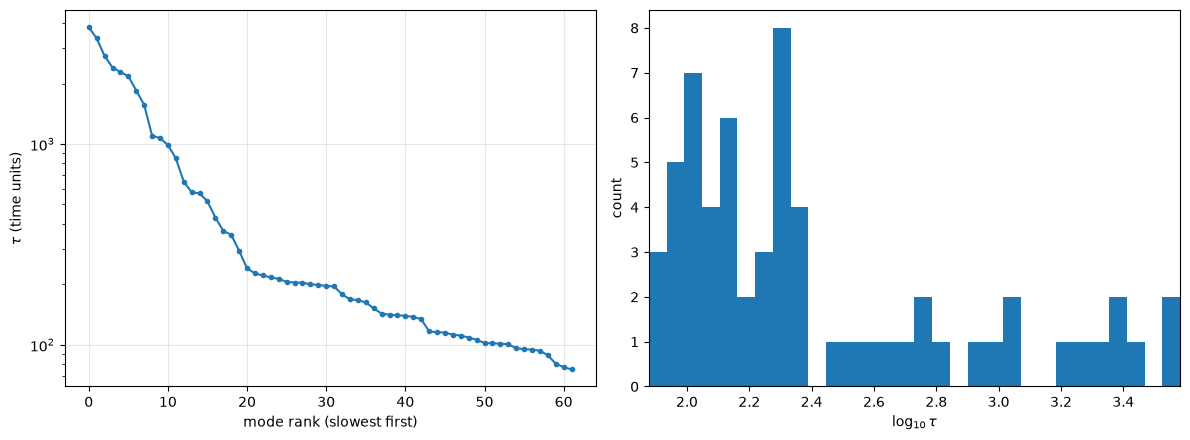

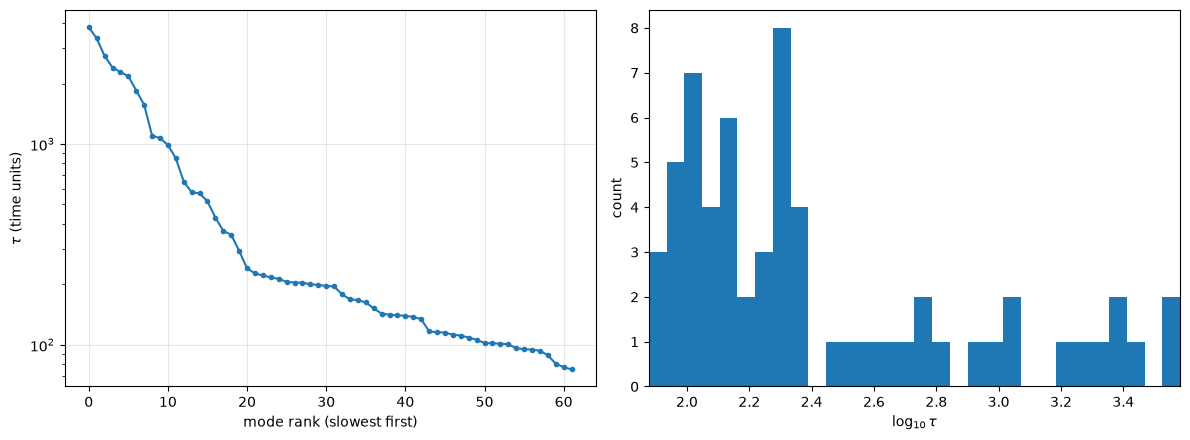

In [14]:

plot_tau(mu, net.dt)

In [15]:
alpha_a = np.asarray(alpha)[alpha > 0]
leak = np.sort(1 - alpha_a)
r = np.sort(np.abs(mu)); r = r[r > 1e-10]
m = np.array([np.min(np.abs(leak - x)) for x in r])
print("modes matching a leak value (1e-6):", np.sum(m < 1e-6), "of", len(r))
print("slowest:", r[-1], " nearest leak:", leak[np.argmin(np.abs(leak - r[-1]))])

modes matching a leak value (1e-6): 62 of 62
slowest: 0.9756165773564508  nearest leak: 0.9756165773564508


In [16]:
traj = run_zero_input(net, n_steps=20000, v_const=0.0,n_switch=10000)
x_final = traj[-1]

### Activity dimension

In [17]:
ad_esn_dist_decay_net_wide = activity_dimension(traj[net.neurons_out, :10000-200])

### Plot trajectory

(<Figure size 1600x450 with 3 Axes>,)

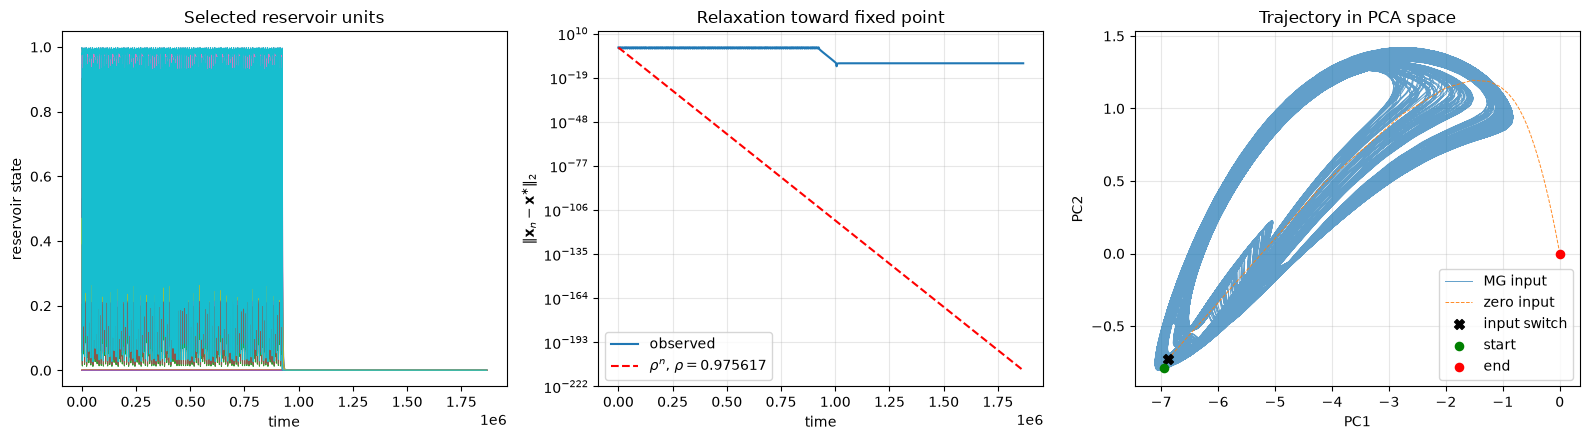

In [18]:
plot_relaxation(traj[net.neurons_out,:], x_star[net.neurons_out], rho=r_a.max(), dt=net.dt, n_units=20,switch_step=10000-200)

## ESN_fixed_decay_net_wide

In [19]:
from reservoirpy.datasets import mackey_glass
net = best_nets_ESN_fixed_decay_net_wide_dict
warmup  = 1000

narma_input = mackey_glass(5000, seed=0)
INPUT = narma_input.T
sim = NetworkSimulator(net)
sim.warmup(narma_input[:warmup])

### Find fixed point

In [20]:
state,converge = settle_to_fixed_point(net, input_constant=[0.0], max_steps=10000, tol=1e-9, consecutive_required=200, verbose=True)
x_star = state[net.neurons_out,]


Step 1: update error = 5.202e+00, consecutive = 0
Step 1001: update error = 5.636e+00, consecutive = 0
Step 2001: update error = 5.636e+00, consecutive = 0
Step 3001: update error = 5.636e+00, consecutive = 0
Step 4001: update error = 5.636e+00, consecutive = 0
Step 5001: update error = 5.636e+00, consecutive = 0
Step 6001: update error = 5.636e+00, consecutive = 0
Step 7001: update error = 5.636e+00, consecutive = 0
Step 8001: update error = 5.636e+00, consecutive = 0
Step 9001: update error = 5.636e+00, consecutive = 0


### Calculate jacobian

In [21]:
alpha = net.decay[net.neurons_out]
# W_by_delay = net.W_masked_list
active = np.asarray(alpha) > 0 # indices of active units
alpha_a = np.asarray(alpha)[active] # decay rates of active units
# x_a = x_star[active] # states of active units
# W_a = [Wd[np.ix_(active, active)] for Wd in W_by_delay] # weight matrices for active units

J_esn, g_a = esn_jacobian(net, x_star,  active_only=True, activation='sigmoid') 
mu_a = np.linalg.eigvals(J_esn)
r_a = np.abs(mu_a)
print("spectral radius (active units):", r_a.max())

spectral radius (active units): 0.12210528786325238


In [22]:
dir_name = 'timescale_factors_MG/'
save_spectrum(mu_a, 'MG', 'ESN','fixed','net_wide', dir_name)

In [23]:
mu = np.linalg.eigvals(J_esn)          # one matrix only
r = np.abs(mu)

print("rho:", r.max(), " -> tau_max:", -net.dt/np.log(r.max()))
print("top 10 |mu|:", np.sort(r)[-10:])

meaningful = (r > 1e-6) & (r < 1 - 1e-12) # indices of meaningful eigenvalues
tau = -net.dt/np.log(r[meaningful]) # time constants for meaningful eigenvalues
print("n meaningful:", meaningful.sum())
print("tau sorted (top 15):", np.sort(tau)[-15:])
print("tau quantiles:", np.quantile(tau, [0.1, 0.5, 0.9, 0.99]))

rho: 0.12210528786325238  -> tau_max: 44.83436104921831
top 10 |mu|: [0.0182813  0.03245291 0.03245291 0.03489359 0.03489359 0.05027658
 0.05428257 0.05428257 0.12210529 0.12210529]
n meaningful: 58
tau sorted (top 15): [23.04796182 23.04796182 23.22009119 23.22009119 23.55917249 23.55917249
 27.50346001 27.50346001 28.0978238  28.0978238  31.52979824 32.3594368
 32.3594368  44.83436105 44.83436105]
tau quantiles: [ 8.87736249 14.92636457 28.0978238  44.83436105]


In [24]:
mu = np.linalg.eigvals(J_esn)
order = np.argsort(np.abs(mu))[::-1]

print("spectral radius:", np.abs(mu).max())
print("largest-magnitude eigenvalues:", mu[order[:20]])

spectral radius: 0.12210528786325238
largest-magnitude eigenvalues: [-0.09533586+0.07629401j -0.09533586-0.07629401j  0.00631691+0.05391377j
  0.00631691-0.05391377j  0.05027658+0.j          0.00752301-0.03407296j
  0.00752301+0.03407296j -0.02489391-0.02082029j -0.02489391+0.02082029j
  0.01539662-0.00985647j  0.01539662+0.00985647j -0.01610726-0.00615604j
 -0.01610726+0.00615604j -0.00912163-0.01402282j -0.00912163+0.01402282j
  0.00306247-0.00965206j  0.00306247+0.00965206j  0.00061567-0.00530641j
  0.00061567+0.00530641j  0.00416713-0.00239509j]


In [25]:
timescale_dict = timescales_from_eigenvalues(net,J_esn, zero_tol=1e-12)

rho: 0.12210528786325238  -> tau_max: 44.83436104921831
top 10 |mu|: [0.0182813  0.03245291 0.03245291 0.03489359 0.03489359 0.05027658
 0.05428257 0.05428257 0.12210529 0.12210529]


### Plot spectral radius

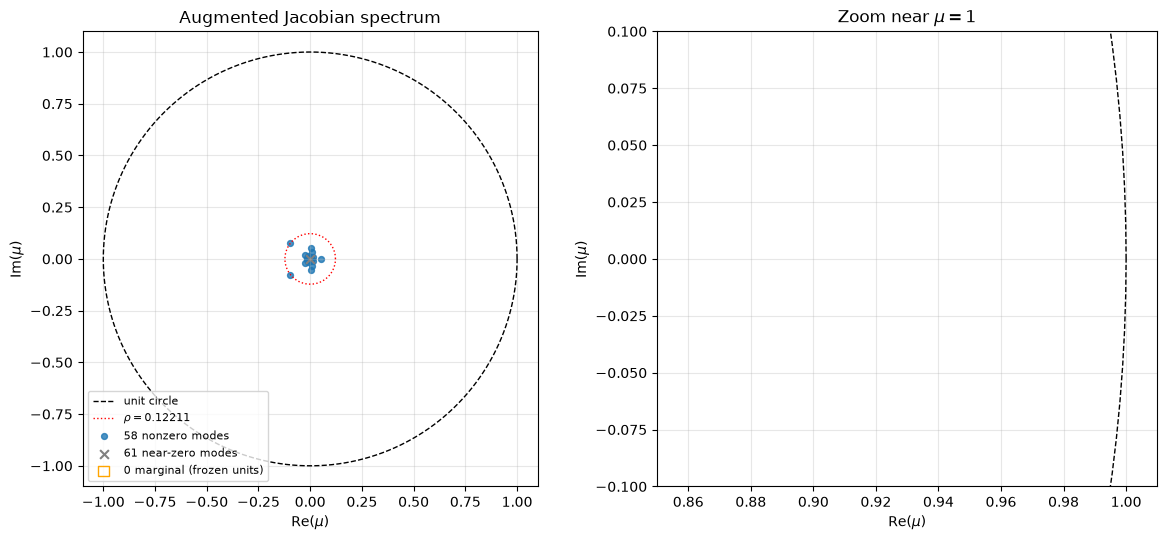

In [26]:

fig = plot_spectrum(mu, mu_full=mu)
# fig.savefig("spectrum.png", dpi=200)

### Plot timescales


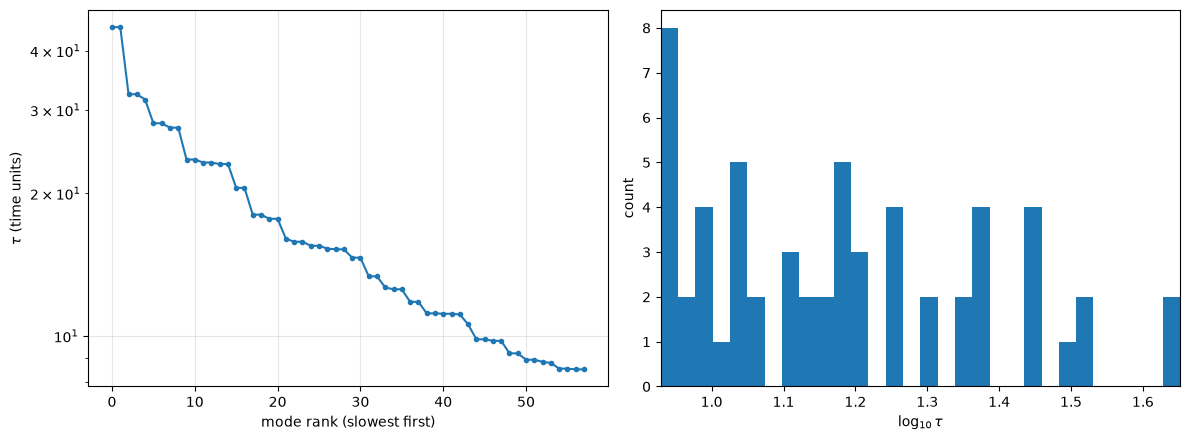

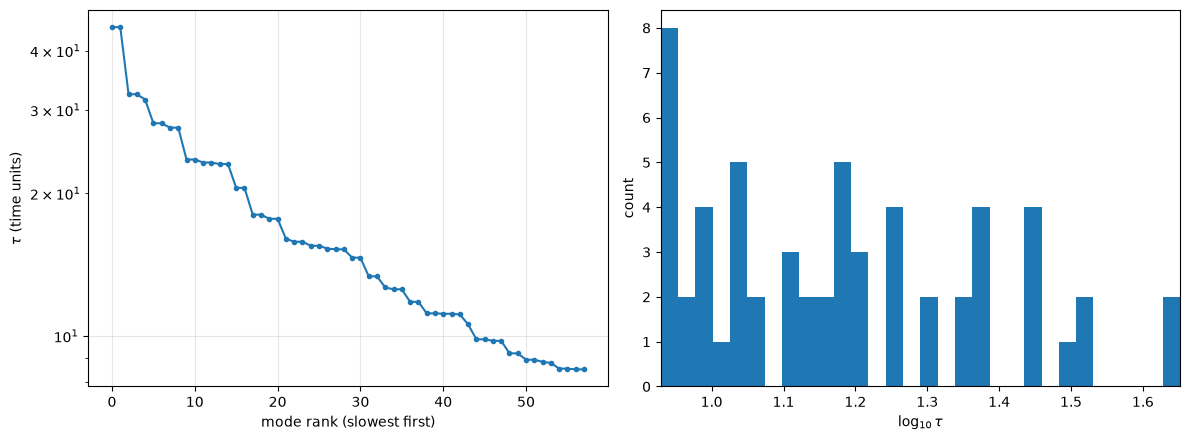

In [27]:

plot_tau(mu, net.dt)

In [28]:
alpha_a = np.asarray(alpha)[alpha > 0]
leak = np.sort(1 - alpha_a)
r = np.sort(np.abs(mu)); r = r[r > 1e-10]
m = np.array([np.min(np.abs(leak - x)) for x in r])
print("modes matching a leak value (1e-6):", np.sum(m < 1e-6), "of", len(r))
print("slowest:", r[-1], " nearest leak:", leak[np.argmin(np.abs(leak - r[-1]))])

modes matching a leak value (1e-6): 2 of 60
slowest: 0.12210528786325238  nearest leak: 0.0


In [29]:
traj = run_zero_input(net, n_steps=20000, v_const=0.0,n_switch=10000)
x_final = traj[-1]

last distance: 3.2586373828676436
largest update over final 100 steps: 6.998476183680554


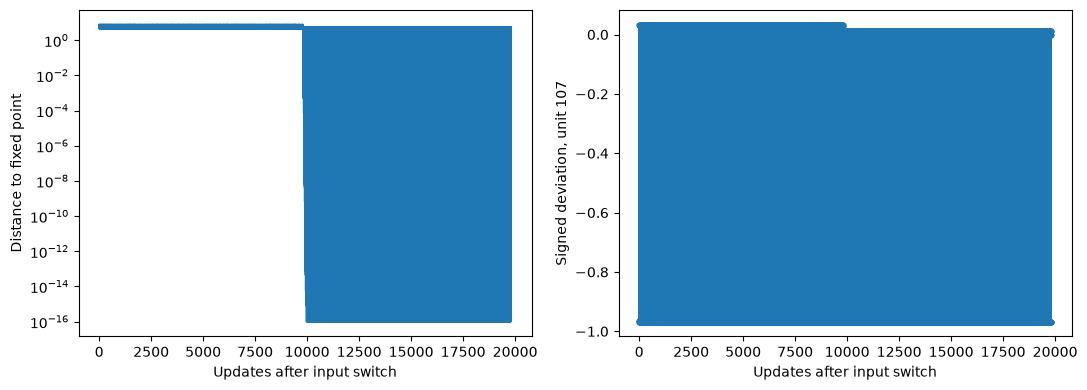

In [30]:
X = np.asarray(traj, dtype=float)
x_ref = np.asarray(x_star, dtype=float).reshape(-1, 1)

delta = X - x_ref
dist = np.linalg.norm(delta, axis=0)
updates = np.linalg.norm(np.diff(X, axis=1), axis=0)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].semilogy(np.maximum(dist, 1e-16))
ax[0].set_xlabel("Updates after input switch")
ax[0].set_ylabel("Distance to fixed point")

# Show the signed deviation of the most variable unit.
i = np.argmax(np.var(delta, axis=1))
ax[1].plot(delta[i], ".-", lw=0.8)
ax[1].set_xlabel("Updates after input switch")
ax[1].set_ylabel(f"Signed deviation, unit {i}")

plt.tight_layout()

print("last distance:", dist[-1])
print("largest update over final 100 steps:", updates[-100:].max())

In [31]:
X = np.asarray(traj[:, 9800:], dtype=float)

for k in (1, 2, 3, 4, 8):
    differences = np.linalg.norm(
        X[:, k:] - X[:, :-k],
        axis=0,
    )
    tail = differences[-100:]

    print(
        f"lag {k}: "
        f"median={np.median(tail):.6e}, "
        f"max={np.max(tail):.6e}"
    )

lag 1: median=6.185442e+00, max=6.998476e+00
lag 2: median=2.361873e+00, max=3.258637e+00
lag 3: median=6.185442e+00, max=6.998476e+00
lag 4: median=8.008880e-16, max=2.975524e-15
lag 8: median=7.385278e-16, max=2.596420e-15


### Activity dimension

In [32]:
ad_esn_fixed_decay_net_wide = activity_dimension(traj[net.neurons_out, :10000-200])

### plot trajectory

(<Figure size 1600x450 with 3 Axes>,)

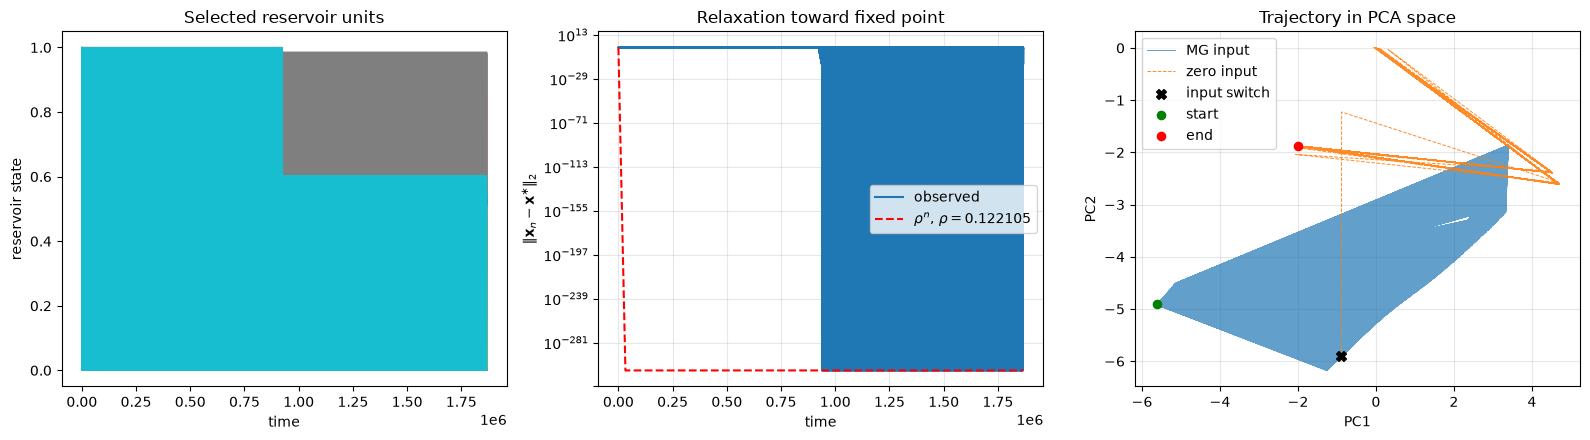

In [33]:
plot_relaxation(traj[net.neurons_out,:], x_star[net.neurons_out], rho=r_a.max(), dt=net.dt, n_units=20,switch_step=10000-200)

## ESN_fixed_decay_per_cluster

In [34]:
from reservoirpy.datasets import mackey_glass
net = best_nets_ESN_fixed_decay_per_cluster_dict
warmup  = 1000

narma_input = mackey_glass(5000, seed=0)
INPUT = narma_input.T
sim = NetworkSimulator(net)
sim.warmup(narma_input[:warmup])

### Find fixed point

In [35]:
state,converge = settle_to_fixed_point(net, input_constant=[0.0], max_steps=10000, tol=1e-9, consecutive_required=200, verbose=True)
x_star = state[net.neurons_out,0]


Step 1: update error = 7.919e-01, consecutive = 0
Converged to fixed point after 421 steps (consecutive = 200).


### Calculate Jacobian

In [36]:
alpha = net.decay[net.neurons_out]
# W_by_delay = net.W_masked_list
active = np.asarray(alpha) > 0 # indices of active units
alpha_a = np.asarray(alpha)[active] # decay rates of active units
# x_a = x_star[active] # states of active units
# W_a = [Wd[np.ix_(active, active)] for Wd in W_by_delay] # weight matrices for active units

J_esn, g_a = esn_jacobian(net, x_star,  active_only=True, activation='sigmoid') 
mu_a = np.linalg.eigvals(J_esn)
r_a = np.abs(mu_a)
print("spectral radius (active units):", r_a.max())

spectral radius (active units): 0.9128407541515259


In [37]:
dir_name = 'timescale_factors_MG/'
save_spectrum(mu_a, 'MG', 'ESN','fixed','per_cluster', dir_name)

In [38]:
mu = np.linalg.eigvals(J_esn)          # one matrix only
r = np.abs(mu)

print("rho:", r.max(), " -> tau_max:", -net.dt/np.log(r.max()))
print("top 10 |mu|:", np.sort(r)[-10:])

meaningful = (r > 1e-6) & (r < 1 - 1e-12) # indices of meaningful eigenvalues
tau = -net.dt/np.log(r[meaningful]) # time constants for meaningful eigenvalues
print("n meaningful:", meaningful.sum())
print("tau sorted (top 15):", np.sort(tau)[-15:])
print("tau quantiles:", np.quantile(tau, [0.1, 0.5, 0.9, 0.99]))

rho: 0.9128407541515259  -> tau_max: 1033.851741902478
top 10 |mu|: [0.83661411 0.83661411 0.83781455 0.83781455 0.83904475 0.83904475
 0.87026078 0.91262973 0.91284075 0.91284075]
n meaningful: 89
tau sorted (top 15): [ 409.01607828  421.67329262  421.67329262  476.76482053  476.76482053
  528.503051    528.503051    532.78540025  532.78540025  537.2399706
  537.2399706   678.46359559 1031.23729979 1033.8517419  1033.8517419 ]
tau quantiles: [ 133.26583361  266.78228788  528.503051   1033.8517419 ]


In [39]:
timescale_dict = timescales_from_eigenvalues(net,J_esn, zero_tol=1e-12)

rho: 0.9128407541515259  -> tau_max: 1033.851741902478
top 10 |mu|: [0.83661411 0.83661411 0.83781455 0.83781455 0.83904475 0.83904475
 0.87026078 0.91262973 0.91284075 0.91284075]


### plot spectral radius

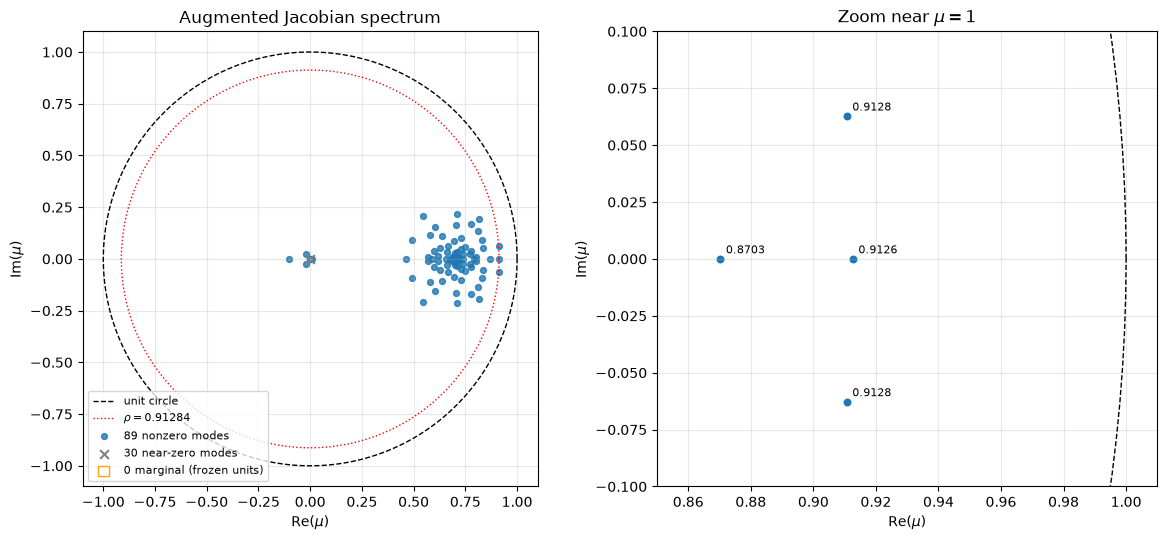

In [40]:

fig = plot_spectrum(mu, mu_full=mu)
# fig.savefig("spectrum.png", dpi=200)

### plot timescales

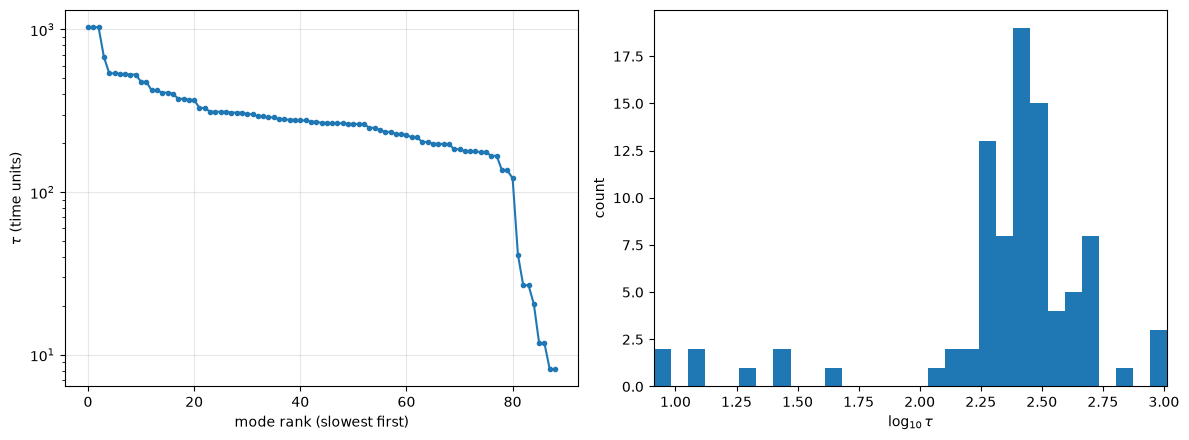

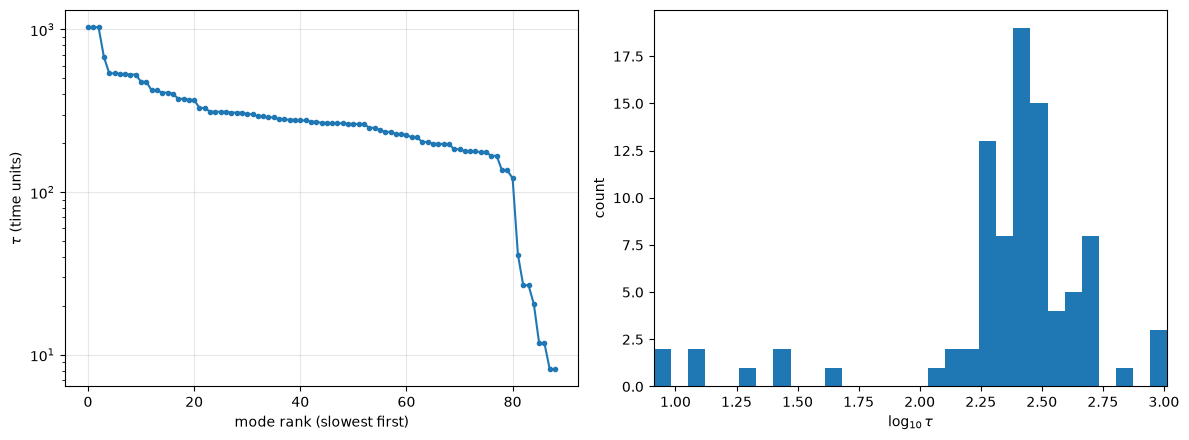

In [41]:

plot_tau(mu, net.dt)

In [42]:
alpha_a = np.asarray(alpha)[alpha > 0]
leak = np.sort(1 - alpha_a)
r = np.sort(np.abs(mu)); r = r[r > 1e-10]
m = np.array([np.min(np.abs(leak - x)) for x in r])
print("modes matching a leak value (1e-6):", np.sum(m < 1e-6), "of", len(r))
print("slowest:", r[-1], " nearest leak:", leak[np.argmin(np.abs(leak - r[-1]))])

modes matching a leak value (1e-6): 10 of 99
slowest: 0.9128407541515259  nearest leak: 0.7070089784068139


In [43]:
traj = run_zero_input(net, n_steps=20000, v_const=0.0,n_switch=10000)
x_final = traj[-1]

### Activity dimension

In [44]:
ad_esn_fixed_decay_per_cluster = activity_dimension(traj[net.neurons_out, :10000-200])

### plot trajectory

(<Figure size 1600x450 with 3 Axes>,)

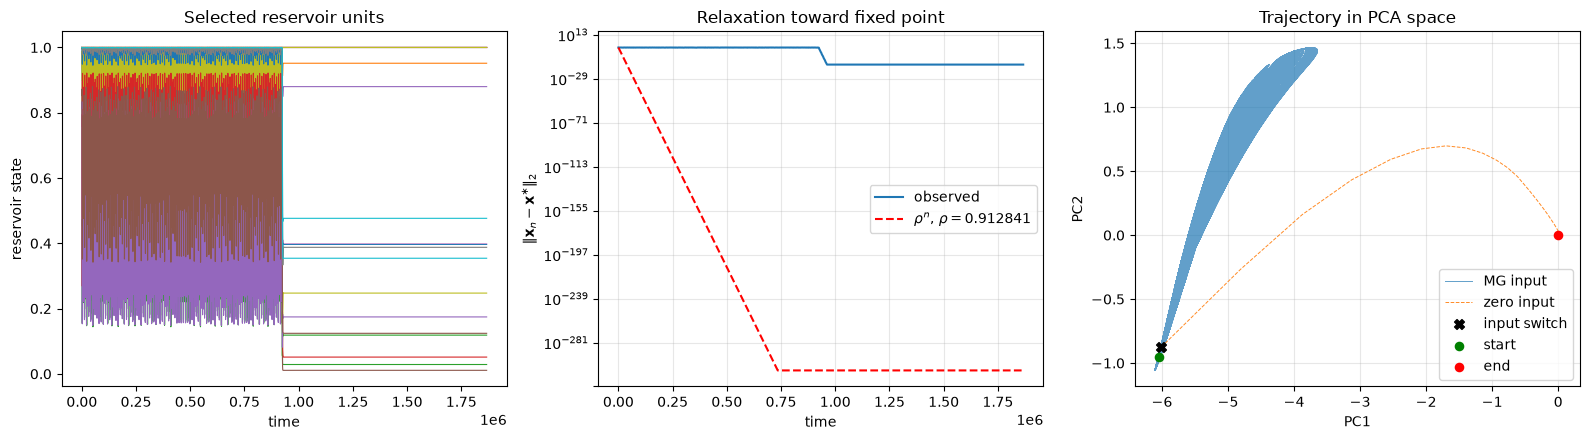

In [45]:
plot_relaxation(traj[net.neurons_out,:], x_star[net.neurons_out], rho=r_a.max(), dt=net.dt, n_units=20,switch_step=10000-200)

## ESN_dist_decay_per_cluster

In [46]:
from reservoirpy.datasets import mackey_glass
net = best_nets_ESN_dist_decay_per_cluster_dict
warmup  = 1000

narma_input = mackey_glass(5000, seed=0)
INPUT = narma_input.T
sim = NetworkSimulator(net)
sim.warmup(narma_input[:warmup])

### Find fixed point

In [47]:
state,converge = settle_to_fixed_point(net, input_constant=[0.0], max_steps=10000, tol=1e-9, consecutive_required=200, verbose=True)
x_star = state[net.neurons_out,0]


Step 1: update error = 8.079e-01, consecutive = 0
Step 1001: update error = 1.918e-06, consecutive = 0
Step 2001: update error = 8.934e-10, consecutive = 15
Converged to fixed point after 2186 steps (consecutive = 200).


### Calculate Jacobian

In [48]:
alpha = net.decay[net.neurons_out]
# W_by_delay = net.W_masked_list
active = np.asarray(alpha) > 0 # indices of active units
alpha_a = np.asarray(alpha)[active] # decay rates of active units
# x_a = x_star[active] # states of active units
# W_a = [Wd[np.ix_(active, active)] for Wd in W_by_delay] # weight matrices for active units

J_esn, g_a = esn_jacobian(net, x_star,  active_only=True, activation='sigmoid') 
mu_a = np.linalg.eigvals(J_esn)
r_a = np.abs(mu_a)
print("spectral radius (active units):", r_a.max())

spectral radius (active units): 0.9923576048919761


In [49]:
dir_name = 'timescale_factors_MG/'
save_spectrum(mu_a, 'MG', 'ESN','dist','per_cluster', dir_name)

In [50]:
mu = np.linalg.eigvals(J_esn)          # one matrix only
r = np.abs(mu)

print("rho:", r.max(), " -> tau_max:", -net.dt/np.log(r.max()))
print("top 10 |mu|:", np.sort(r)[-10:])

meaningful = (r > 1e-6) & (r < 1 - 1e-12) # indices of meaningful eigenvalues
tau = -net.dt/np.log(r[meaningful]) # time constants for meaningful eigenvalues
print("n meaningful:", meaningful.sum())
print("tau sorted (top 15):", np.sort(tau)[-15:])
print("tau quantiles:", np.quantile(tau, [0.1, 0.5, 0.9, 0.99]))

rho: 0.9923576048919761  -> tau_max: 12289.3642929761
top 10 |mu|: [0.92335616 0.92396841 0.92757073 0.94226206 0.95205717 0.96281897
 0.96481934 0.96637306 0.97380876 0.9923576 ]
n meaningful: 67
tau sorted (top 15): [  759.69151932   815.34251304   917.36495998   948.42098459
  1158.04021112  1182.35034164  1192.26110134  1253.96509581
  1585.30309663  1919.0012822   2488.28813884  2632.48540344
  2756.32234253  3552.36196224 12289.36429298]
tau quantiles: [ 127.39102563  347.09872006 1386.50029614 6522.94275469]


In [51]:
timescale_dict = timescales_from_eigenvalues(net,J_esn, zero_tol=1e-12)

rho: 0.9923576048919761  -> tau_max: 12289.3642929761
top 10 |mu|: [0.92335616 0.92396841 0.92757073 0.94226206 0.95205717 0.96281897
 0.96481934 0.96637306 0.97380876 0.9923576 ]


### plot spectral radius

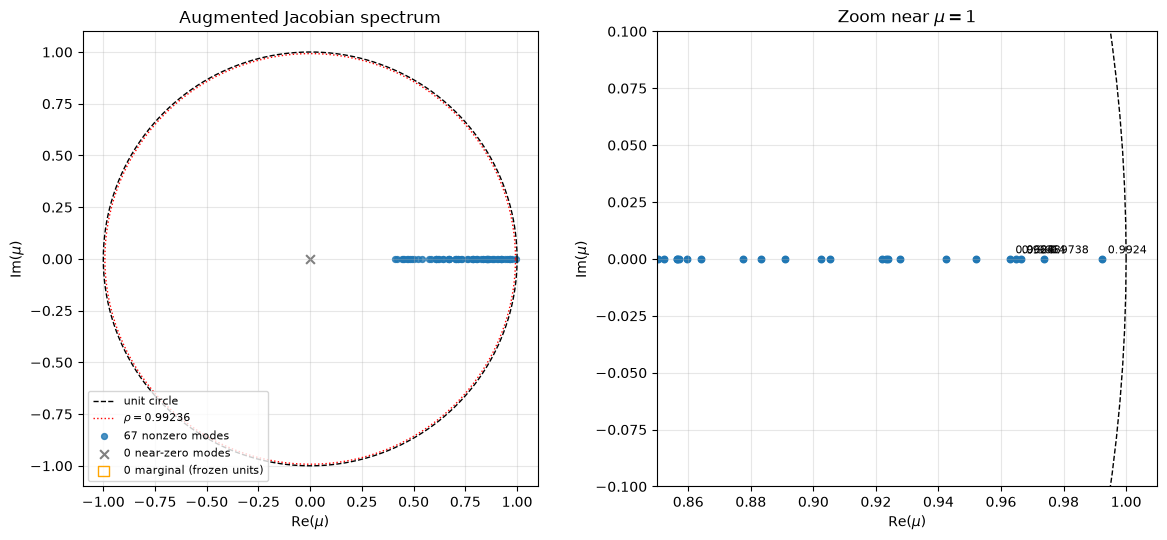

In [52]:

fig = plot_spectrum(mu, mu_full=mu)
# fig.savefig("spectrum.png", dpi=200)

### plot timescales

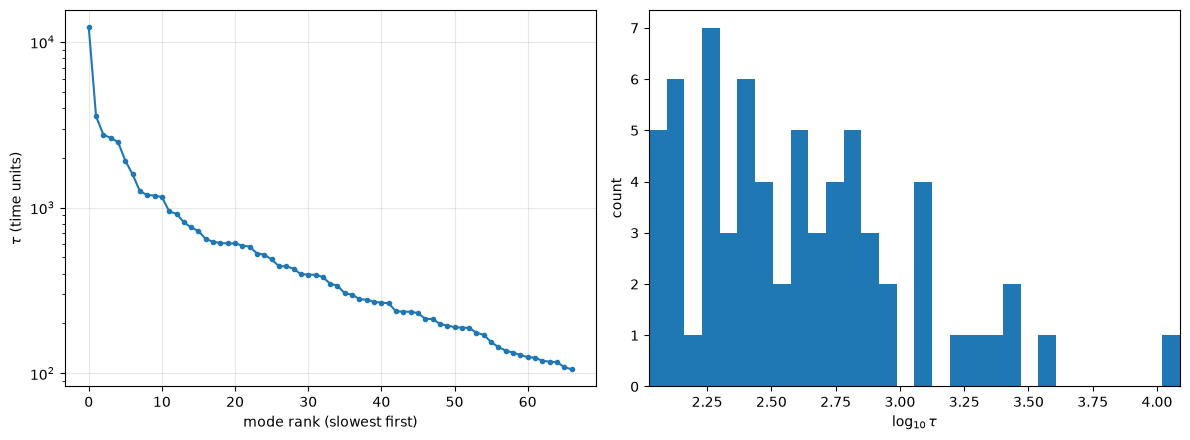

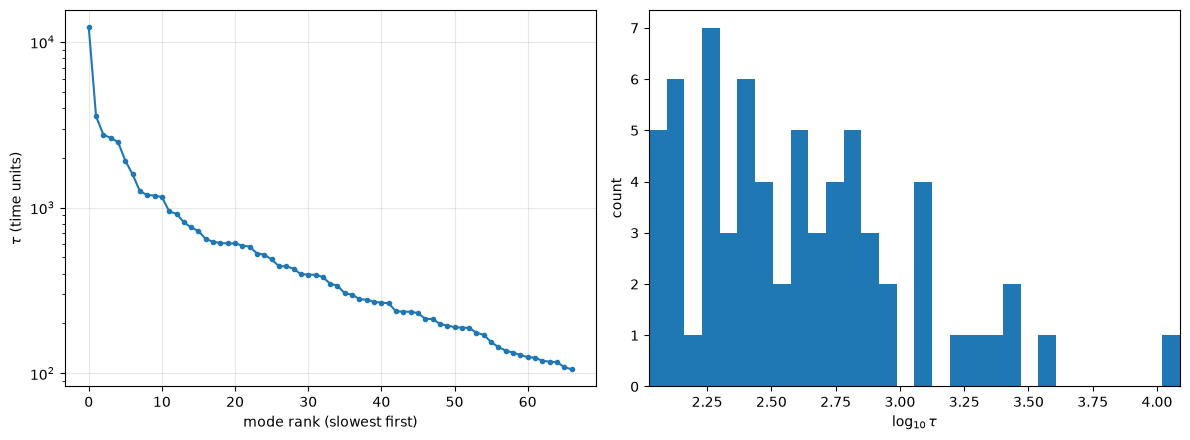

In [53]:

plot_tau(mu, net.dt)

In [54]:
alpha_a = np.asarray(alpha)[alpha > 0]
leak = np.sort(1 - alpha_a)
r = np.sort(np.abs(mu)); r = r[r > 1e-10]
m = np.array([np.min(np.abs(leak - x)) for x in r])
print("modes matching a leak value (1e-6):", np.sum(m < 1e-6), "of", len(r))
print("slowest:", r[-1], " nearest leak:", leak[np.argmin(np.abs(leak - r[-1]))])

modes matching a leak value (1e-6): 67 of 67
slowest: 0.9923576048919761  nearest leak: 0.9923576048919761


In [55]:
traj = run_zero_input(net, n_steps=20000, v_const=0.0,n_switch=10000)
x_final = traj[-1]

### Activity dimension

In [56]:
ad_esn_dist_decay_per_cluster = activity_dimension(traj[net.neurons_out, :10000-200])

### plot trajectory

(<Figure size 1600x450 with 3 Axes>,)

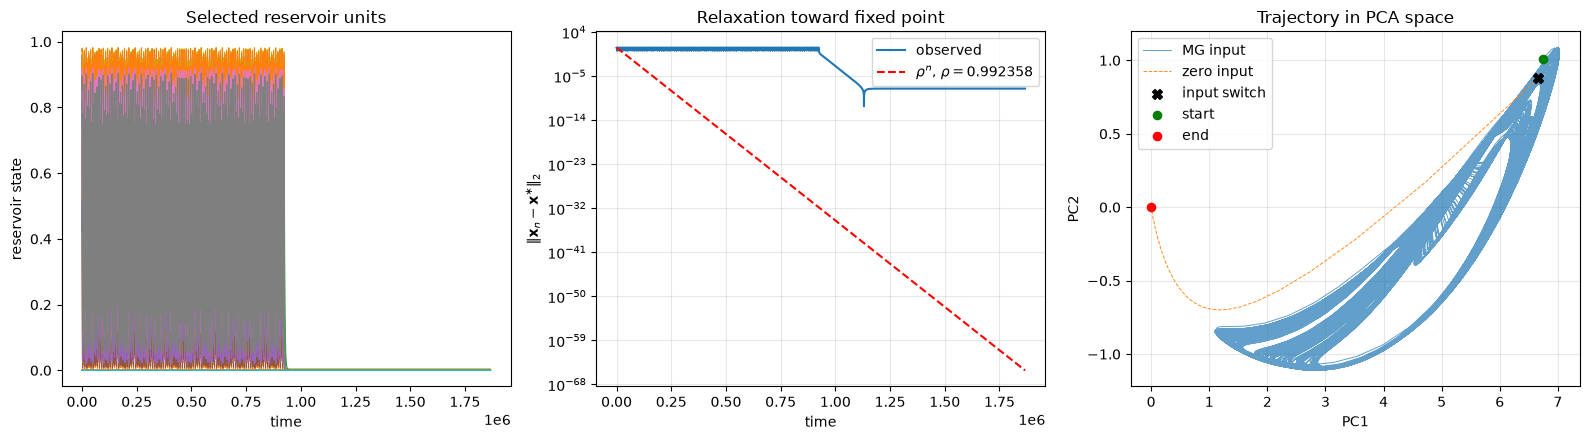

In [57]:
plot_relaxation(traj[net.neurons_out,:], x_star[net.neurons_out], rho=r_a.max(), dt=net.dt, n_units=20,switch_step=10000-200)

## DDN_fixed_decay_per_cluster

In [77]:
from reservoirpy.datasets import mackey_glass
net = best_nets_DDN_fixed_decay_per_cluster_dict
warmup  = 1000

narma_input = mackey_glass(5000, seed=0)
INPUT = narma_input.T
sim = NetworkSimulator(net)
sim.warmup(narma_input[:warmup])

### Find fixed point

In [84]:
state,converge = settle_to_fixed_point(net, input_constant=[0.0], max_steps=10000, tol=1e-9, consecutive_required=200,)
x_star = state[net.neurons_out,0]


### Calculate Jacobian

In [90]:
alpha = net.decay[net.neurons_out]
W_by_delay = net.W_masked_list
active = np.asarray(alpha) > 0 # indices of active units
alpha_a = np.asarray(alpha)[active] # decay rates of active units
x_a = x_star[active] # states of active units
W_a = [Wd[np.ix_(active, active)] for Wd in W_by_delay] # weight matrices for active units

J_blocks_a, g_a = delayed_esn_jacobian_blocks(W_a, alpha_a, x_a,activation = 'sigmoid') 
J_aug_a = augmented_jacobian(J_blocks_a)
mu_a = np.linalg.eigvals(J_aug_a)
r_a = np.abs(mu_a)
print("spectral radius (active units):", r_a.max())

spectral radius (active units): 0.9963851959792616


In [91]:
dir_name = 'timescale_factors_MG/'
save_spectrum(mu_a, 'MG', 'DDN','fixed','per_cluster', dir_name)

In [94]:
mu = np.linalg.eigvals(J_aug_a)          # one matrix only
r = np.abs(mu)

print("rho:", r.max(), " -> tau_max:", -net.dt/np.log(r.max()))
print("top 10 |mu|:", np.sort(r)[-10:])

meaningful = (r > 1e-6) & (r < 1 - 1e-12) # indices of meaningful eigenvalues
tau = -net.dt/np.log(r[meaningful]) # time constants for meaningful eigenvalues
print("n meaningful:", meaningful.sum())
print("tau sorted (top 15):", np.sort(tau)[-15:])
print("tau quantiles:", np.quantile(tau, [0.1, 0.5, 0.9, 0.99]))

rho: 0.9963851959792616  -> tau_max: 1.4463731378282414
top 10 |mu|: [0.90218019 0.90304838 0.91982971 0.92911756 0.93232737 0.95419384
 0.95877261 0.96693018 0.99377256 0.9963852 ]
n meaningful: 96
tau sorted (top 15): [0.04127302 0.04142121 0.04148986 0.04184601 0.04217242 0.05088184
 0.05136175 0.06267839 0.07124357 0.07475    0.1117083  0.12441
 0.15575337 0.83846642 1.44637314]
tau quantiles: [0.00415336 0.01003286 0.04652713 0.86886176]


In [95]:
timescale_dict = timescales_from_eigenvalues(net,J_aug_a, zero_tol=1e-12)

rho: 0.9963851959792616  -> tau_max: 1.4463731378282414
top 10 |mu|: [0.90218019 0.90304838 0.91982971 0.92911756 0.93232737 0.95419384
 0.95877261 0.96693018 0.99377256 0.9963852 ]


### Plot Spectral Radius

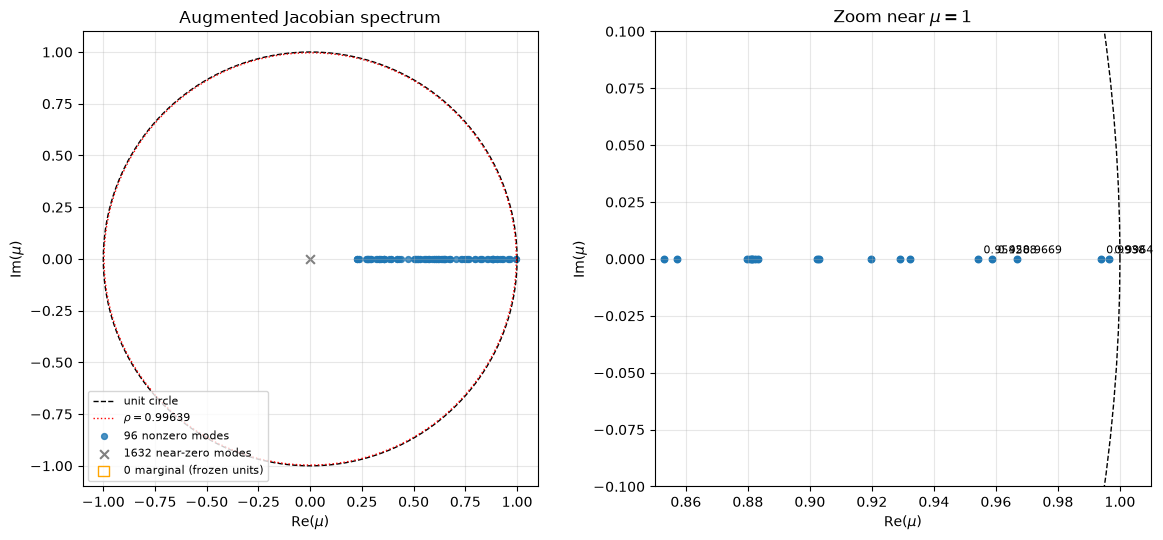

In [96]:

fig = plot_spectrum(mu, mu_full=mu)
# fig.savefig("spectrum.png", dpi=200)

### Plot timescales

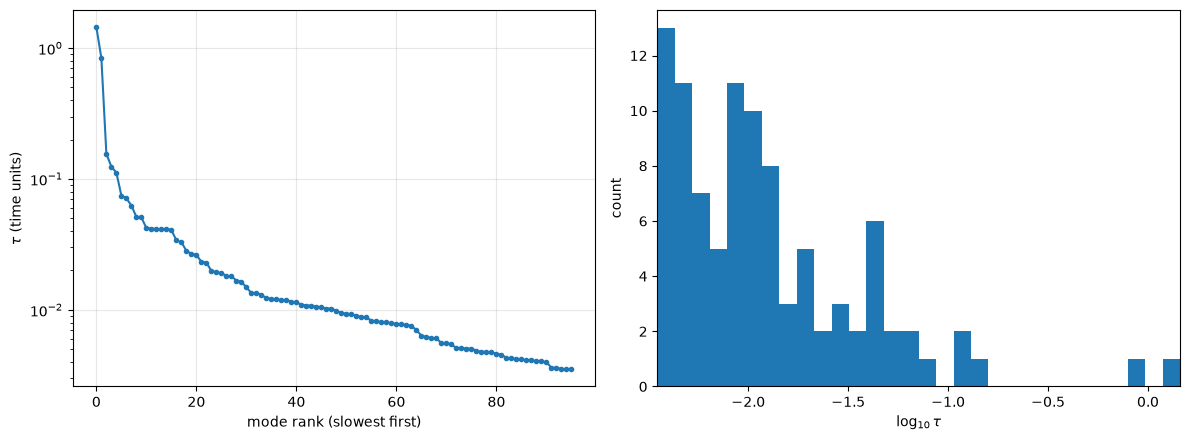

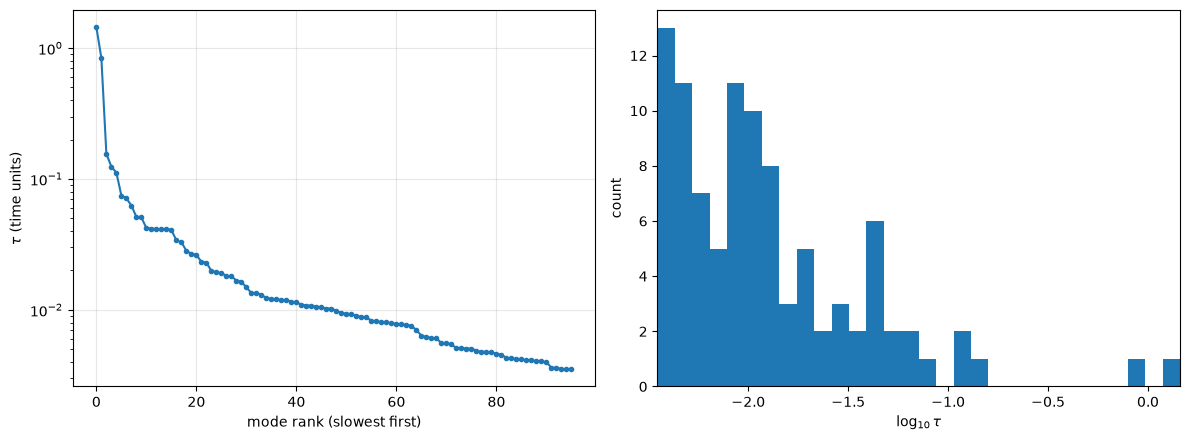

In [97]:

plot_tau(mu, net.dt)

In [98]:
alpha_a = np.asarray(alpha)[alpha > 0]
leak = np.sort(1 - alpha_a)
r = np.sort(np.abs(mu)); r = r[r > 1e-10]
m = np.array([np.min(np.abs(leak - x)) for x in r])
print("modes matching a leak value (1e-6):", np.sum(m < 1e-6), "of", len(r))
print("slowest:", r[-1], " nearest leak:", leak[np.argmin(np.abs(leak - r[-1]))])

modes matching a leak value (1e-6): 96 of 96
slowest: 0.9963851959792616  nearest leak: 0.9963851959792616


In [99]:
alpha_a = np.asarray(alpha)[alpha > 0]
act = alpha > 0

J0 = J_blocks_a[0]
diag_leak = np.diag(1 - alpha_a)

print("||J0 - diag(1-alpha)||_F :", np.linalg.norm(J0 - diag_leak))
for d, Jd in enumerate(J_blocks_a[1:], start=1):
    print(f"||J_{d}||_F:", np.linalg.norm(Jd))

for d, Wd in enumerate(W_by_delay):
    print(f"d={d} nnz(W_d)={np.count_nonzero(Wd)}  ||W_d||_F={np.linalg.norm(Wd):.3e}")

R = J0 - diag_leak
print("spectral radius of recurrent part:", np.max(np.abs(np.linalg.eigvals(R))))

||J0 - diag(1-alpha)||_F : 0.0
||J_1||_F: 0.0
||J_2||_F: 0.0
||J_3||_F: 0.0
||J_4||_F: 0.0
||J_5||_F: 0.0
||J_6||_F: 0.0
||J_7||_F: 0.0
||J_8||_F: 0.0
||J_9||_F: 0.0
||J_10||_F: 0.0
||J_11||_F: 0.0
||J_12||_F: 0.0
||J_13||_F: 0.0
||J_14||_F: 0.0
||J_15||_F: 0.0
||J_16||_F: 0.0
||J_17||_F: 0.0
d=0 nnz(W_d)=1  ||W_d||_F=9.981e-02
d=1 nnz(W_d)=0  ||W_d||_F=0.000e+00
d=2 nnz(W_d)=0  ||W_d||_F=0.000e+00
d=3 nnz(W_d)=0  ||W_d||_F=0.000e+00
d=4 nnz(W_d)=0  ||W_d||_F=0.000e+00
d=5 nnz(W_d)=0  ||W_d||_F=0.000e+00
d=6 nnz(W_d)=0  ||W_d||_F=0.000e+00
d=7 nnz(W_d)=0  ||W_d||_F=0.000e+00
d=8 nnz(W_d)=0  ||W_d||_F=0.000e+00
d=9 nnz(W_d)=0  ||W_d||_F=0.000e+00
d=10 nnz(W_d)=0  ||W_d||_F=0.000e+00
d=11 nnz(W_d)=36  ||W_d||_F=3.861e+01
d=12 nnz(W_d)=73  ||W_d||_F=5.394e+01
d=13 nnz(W_d)=18  ||W_d||_F=2.832e+01
d=14 nnz(W_d)=6  ||W_d||_F=1.572e+01
d=15 nnz(W_d)=0  ||W_d||_F=0.000e+00
d=16 nnz(W_d)=0  ||W_d||_F=0.000e+00
d=17 nnz(W_d)=0  ||W_d||_F=0.000e+00
spectral radius of recurrent part: 0.0


In [100]:
traj = run_zero_input(net, n_steps=20000, v_const=0.0,n_switch=10000)
x_final = traj[-1]

### Activity dimension

In [101]:
ad_ddn_fixed_decay_per_cluster = activity_dimension(traj[net.neurons_out, :10000-200])

In [102]:
switch_step = 10000

# Adjust by one if the recorded trajectory includes the initial state.
traj_zero = np.asarray(traj[net.neurons_out, switch_step:], dtype=float)
x_ref = np.asarray(x_star[net.neurons_out], dtype=float).reshape(-1, 1)

dist = np.linalg.norm(traj_zero - x_ref, axis=0)
update_dist = np.linalg.norm(np.diff(traj_zero, axis=1), axis=0)

print("distance to x_star, first/last:", dist[0], dist[-1])
print("distance range:", dist.min(), dist.max())
print("last maximum update:", update_dist[-100:].max())

distance to x_star, first/last: 0.38662868974955933 1.3619277927645612e-09
distance range: 7.448486272210175e-13 0.38662868974955933
last maximum update: 0.0


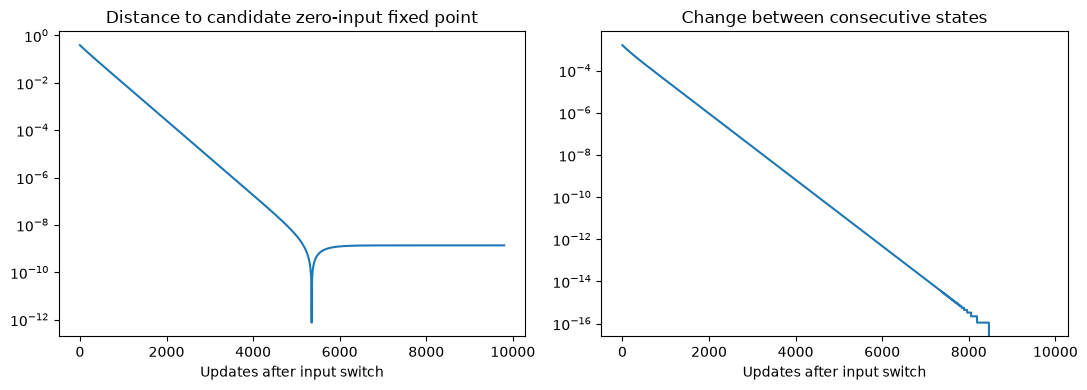

In [103]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].semilogy(dist)
ax[0].set_yscale('log')
ax[0].set_title("Distance to candidate zero-input fixed point")
ax[0].set_xlabel("Updates after input switch")

ax[1].set_yscale('log')
ax[1].semilogy(update_dist)
ax[1].set_title("Change between consecutive states")
ax[1].set_xlabel("Updates after input switch")

plt.tight_layout()

### Plot trajectory

(<Figure size 1600x450 with 3 Axes>,)

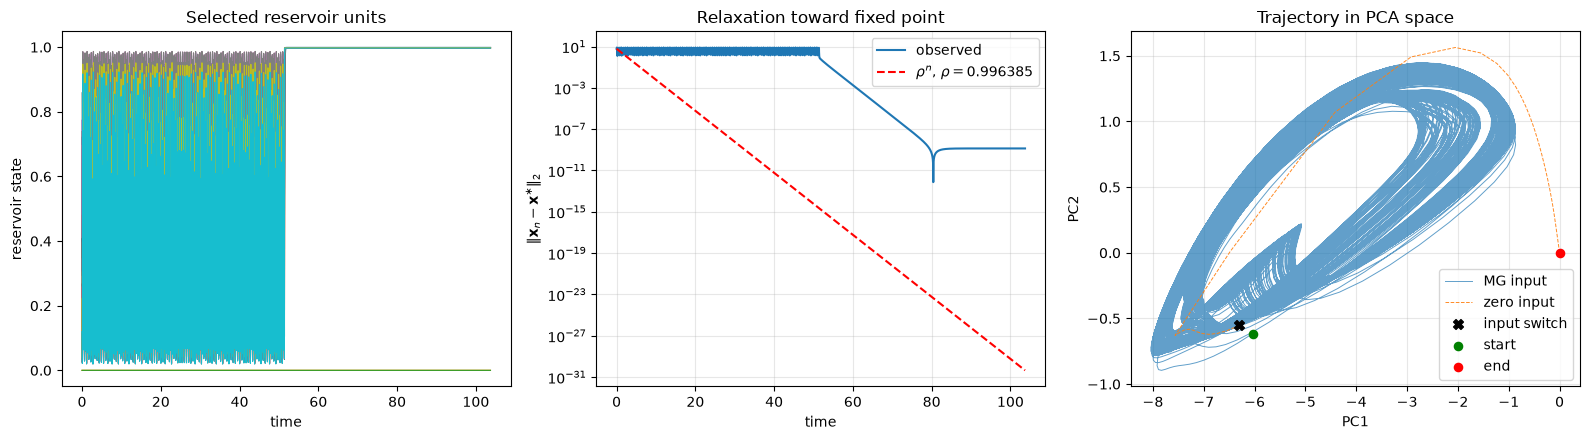

In [104]:
plot_relaxation(traj[net.neurons_out,:], x_star[net.neurons_out], rho=r_a.max(), dt=net.dt, n_units=20,switch_step=10000-200)

## DDN_dist_decay_per_cluster

In [105]:
from reservoirpy.datasets import mackey_glass
net = best_nets_DDN_dist_decay_per_cluster_dict
warmup  = 200

narma_input = mackey_glass(5000, seed=0)
INPUT = narma_input.T
sim = NetworkSimulator(net)
sim.warmup(narma_input[:warmup])

### Find fixedpoints 

In [108]:
state,_ = settle_to_fixed_point(net, input_constant=[0.0], max_steps=10000, tol=1e-9, consecutive_required=100)
x_star = state[net.neurons_out,0]

### Calculate augmented jacobian

In [109]:
alpha = net.decay[net.neurons_out]
W_by_delay = net.W_masked_list
active = np.asarray(alpha) > 0
alpha_a = np.asarray(alpha)[active]
x_a = x_star[active]
W_a = [Wd[np.ix_(active, active)] for Wd in W_by_delay]

J_blocks_a, g_a = delayed_esn_jacobian_blocks(W_a, alpha_a, x_a, activation='sigmoid')
J_aug_a = augmented_jacobian(J_blocks_a)
mu_a = np.linalg.eigvals(J_aug_a)
r_a = np.abs(mu_a)
print("spectral radius (active units):", r_a.max())

spectral radius (active units): 0.9499317755672145


In [110]:
dir_name = 'timescale_factors_MG/'
save_spectrum(mu_a, 'MG', 'DDN','dist','per_cluster', dir_name)

In [111]:
mu = np.linalg.eigvals(J_aug_a)          # one matrix only
r = np.abs(mu)

print("rho:", r.max(), " -> tau_max:", -net.dt/np.log(r.max()))
print("top 10 |mu|:", np.sort(r)[-10:])

meaningful = (r > 1e-6) & (r < 1 - 1e-12)
tau = -net.dt/np.log(r[meaningful])
print("n meaningful:", meaningful.sum())
print("tau sorted (top 15):", np.sort(tau)[-15:])
print("tau quantiles:", np.quantile(tau, [0.1, 0.5, 0.9, 0.99]))

rho: 0.9499317755672145  -> tau_max: 0.10197248265704086
top 10 |mu|: [0.91721204 0.91850817 0.91867211 0.91956667 0.92986814 0.93138749
 0.93364786 0.94162066 0.94955665 0.94993178]
n meaningful: 119
tau sorted (top 15): [0.05019147 0.05396277 0.05408465 0.05587159 0.05861832 0.06061136
 0.06161826 0.0617479  0.06246461 0.07203478 0.07368932 0.07629098
 0.0870754  0.10119435 0.10197248]
tau quantiles: [0.00816675 0.01638423 0.05444204 0.09865294]


In [112]:
timescale_dict = timescales_from_eigenvalues(net,J_aug_a, zero_tol=1e-12)

rho: 0.9499317755672145  -> tau_max: 0.10197248265704086
top 10 |mu|: [0.91721204 0.91850817 0.91867211 0.91956667 0.92986814 0.93138749
 0.93364786 0.94162066 0.94955665 0.94993178]


### plot spectral radius

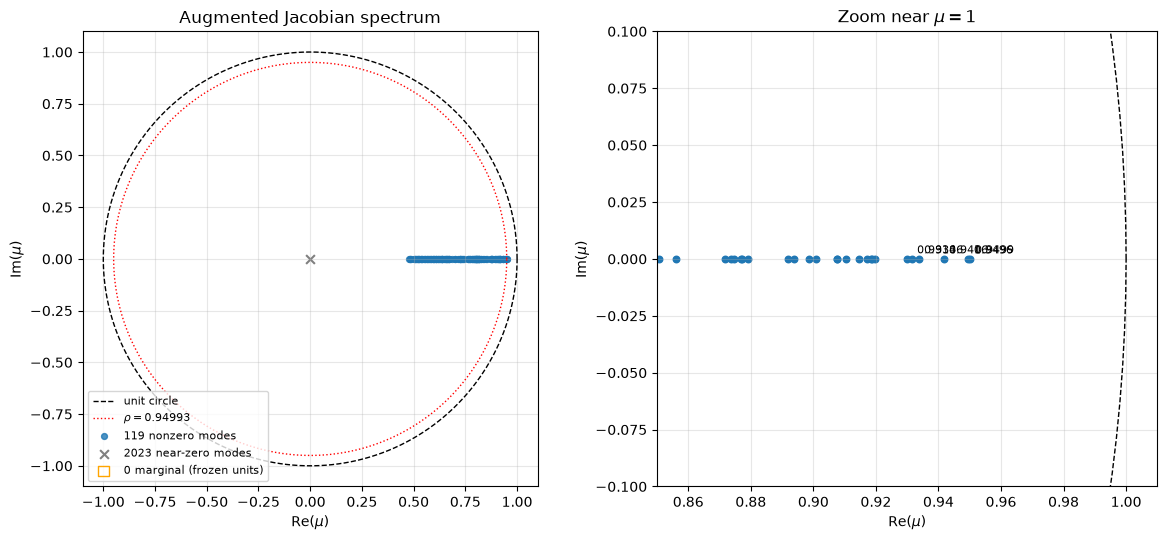

In [113]:

fig = plot_spectrum(mu, mu_full=mu)
# fig.savefig("spectrum.png", dpi=200)

### Plot timescales

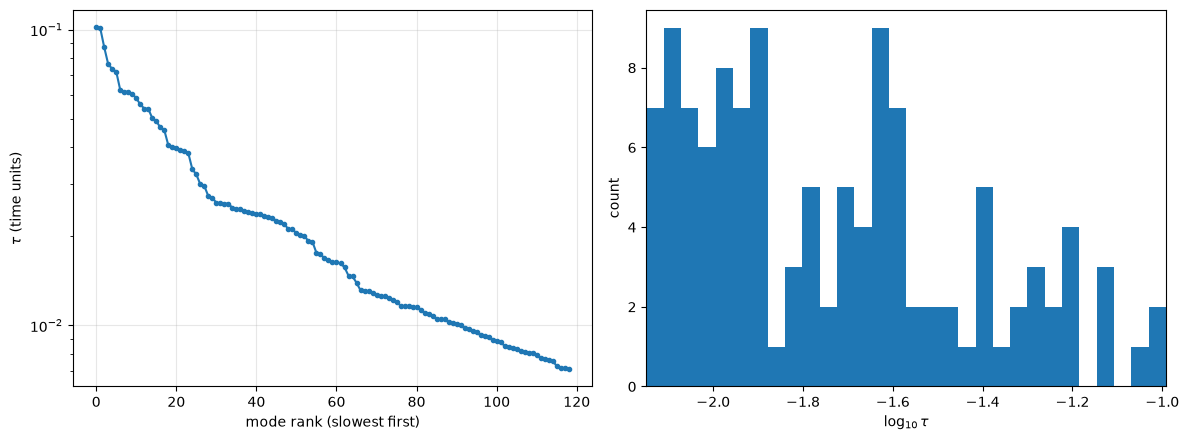

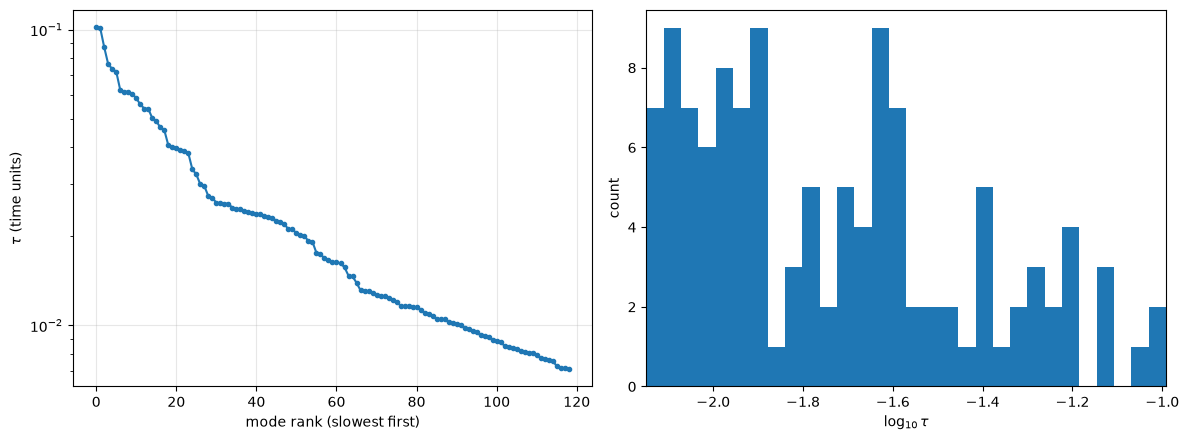

In [114]:

plot_tau(mu, net.dt)

In [115]:
alpha_a = np.asarray(alpha)[alpha > 0]
leak = np.sort(1 - alpha_a)
r = np.sort(np.abs(mu)); r = r[r > 1e-10]
m = np.array([np.min(np.abs(leak - x)) for x in r])
print("modes matching a leak value (1e-6):", np.sum(m < 1e-6), "of", len(r))
print("slowest:", r[-1], " nearest leak:", leak[np.argmin(np.abs(leak - r[-1]))])

modes matching a leak value (1e-6): 119 of 119
slowest: 0.9499317755672145  nearest leak: 0.9499317755672145


In [116]:
alpha_a = np.asarray(alpha)[alpha > 0]
act = alpha > 0

J0 = J_blocks_a[0]
diag_leak = np.diag(1 - alpha_a)

print("||J0 - diag(1-alpha)||_F :", np.linalg.norm(J0 - diag_leak))
for d, Jd in enumerate(J_blocks_a[1:], start=1):
    print(f"||J_{d}||_F:", np.linalg.norm(Jd))

for d, Wd in enumerate(W_by_delay):
    print(f"d={d} nnz(W_d)={np.count_nonzero(Wd)}  ||W_d||_F={np.linalg.norm(Wd):.3e}")

R = J0 - diag_leak
print("spectral radius of recurrent part:", np.max(np.abs(np.linalg.eigvals(R))))

||J0 - diag(1-alpha)||_F : 0.17989815994548097
||J_1||_F: 0.06443781408316016
||J_2||_F: 0.07716633421248809
||J_3||_F: 0.08243646554493382
||J_4||_F: 0.04679316773922657
||J_5||_F: 0.08433834168805841
||J_6||_F: 0.13579149283157718
||J_7||_F: 0.0697736839658609
||J_8||_F: 0.1182855624727475
||J_9||_F: 0.06672733206188036
||J_10||_F: 0.08128920989051534
||J_11||_F: 0.07681168687472185
||J_12||_F: 0.061263623378720634
||J_13||_F: 0.3412649714327935
||J_14||_F: 0.1612558220164192
||J_15||_F: 0.15835171187709268
||J_16||_F: 0.11361764540066815
||J_17||_F: 0.0763940360547985
d=0 nnz(W_d)=216  ||W_d||_F=1.788e+01
d=1 nnz(W_d)=54  ||W_d||_F=3.845e+01
d=2 nnz(W_d)=42  ||W_d||_F=1.680e+01
d=3 nnz(W_d)=43  ||W_d||_F=1.506e+01
d=4 nnz(W_d)=14  ||W_d||_F=1.060e+01
d=5 nnz(W_d)=48  ||W_d||_F=1.606e+01
d=6 nnz(W_d)=83  ||W_d||_F=1.300e+01
d=7 nnz(W_d)=38  ||W_d||_F=1.915e+01
d=8 nnz(W_d)=107  ||W_d||_F=1.790e+01
d=9 nnz(W_d)=40  ||W_d||_F=9.255e+00
d=10 nnz(W_d)=75  ||W_d||_F=1.639e+01
d=11 nnz(W_d

In [117]:

traj = run_zero_input(net, n_steps=20000, v_const=0.0,n_switch=10000)
x_final = traj[-1]



### activity dimension

In [118]:
ad_ddn_dist_decay_per_cluster = activity_dimension(traj[net.neurons_out, :10000-200])

### plot trajectory 

(<Figure size 1600x450 with 3 Axes>,)

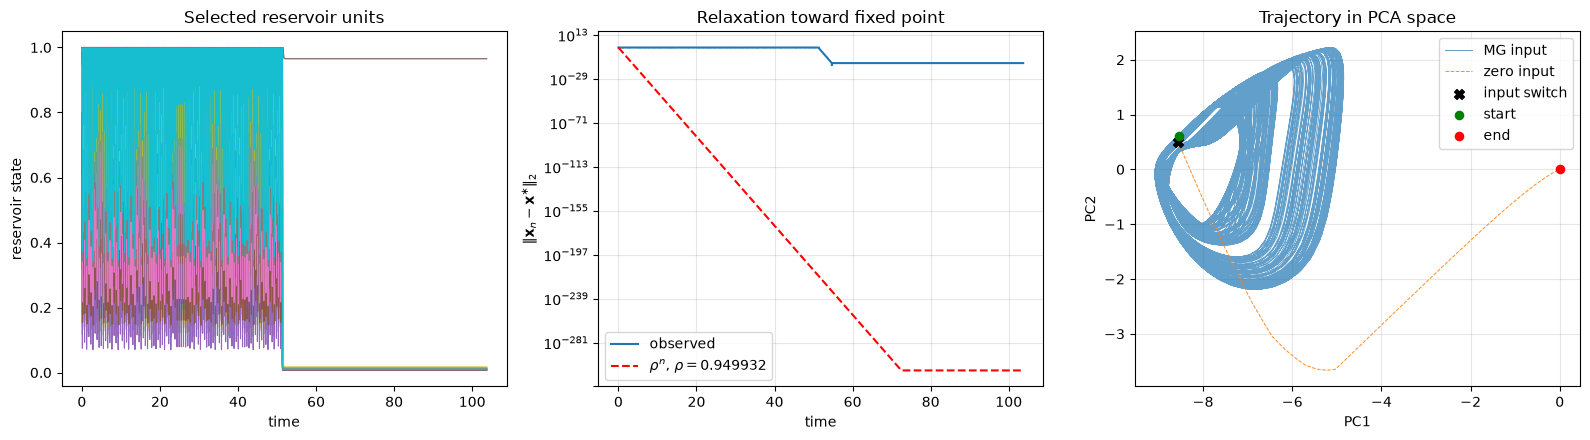

In [119]:
plot_relaxation(traj[net.neurons_out,:], x_star[net.neurons_out], rho=r_a.max(), dt=net.dt, n_units=20,switch_step=10000-200)

## DDN_fixed_decay_net_wide

In [120]:
from reservoirpy.datasets import mackey_glass
net = best_nets_DDN_fixed_decay_net_wide_dict
warmup  = 200

narma_input = mackey_glass(5000, seed=0)
INPUT = narma_input.T
sim = NetworkSimulator(net)
sim.warmup(narma_input[:warmup])

### Find fixedpoints 

In [121]:
state,_ = settle_to_fixed_point(net, input_constant=[0.0], max_steps=10000, tol=1e-9, consecutive_required=100)
x_star = state[net.neurons_out,0]

### Calculate augmented jacobian


In [122]:
alpha = net.decay[net.neurons_out]
W_by_delay = net.W_masked_list
active = np.asarray(alpha) > 0
alpha_a = np.asarray(alpha)[active]
x_a = x_star[active]
W_a = [Wd[np.ix_(active, active)] for Wd in W_by_delay]

J_blocks_a, g_a = delayed_esn_jacobian_blocks(W_a, alpha_a, x_a, activation='sigmoid')
J_aug_a = augmented_jacobian(J_blocks_a)
mu_a = np.linalg.eigvals(J_aug_a)
r_a = np.abs(mu_a)
print("spectral radius (active units):", r_a.max())

spectral radius (active units): 0.9261456040692431


In [123]:
dir_name = 'timescale_factors_MG/'
save_spectrum(mu_a, 'MG', 'DDN','fixed','net_wide', dir_name)

In [124]:
# Use the Jacobian for the network you are currently analyzing.
J = np.asarray(J_aug_a)
mu = np.linalg.eigvals(J)
mag = np.abs(mu)

zero_tol = 1e-12
meaningful = mag > zero_tol
stable = meaningful & (mag < 1.0)

mu_meaningful = mu[meaningful]
mag_meaningful = mag[meaningful]

rho = mag.max()
tau_stable = -net.dt / np.log(mag[stable])

order = np.argsort(mag)[::-1]

print("Jacobian shape:", J.shape)
print("dt:", net.dt)
print("n total:", mu.size)
print("n zero/near-zero:", np.count_nonzero(~meaningful))
print("n meaningful:", np.count_nonzero(meaningful))
print("n meaningful with |mu| >= 1:",
      np.count_nonzero(meaningful & (mag >= 1.0)))
print("rho:", f"{rho:.16e}")

with np.printoptions(precision=16, suppress=False):
    print("largest 15 eigenvalues:", mu[order[:15]])
    print("largest 15 magnitudes:", mag[order[:15]])

    if mag_meaningful.size:
        print(
            "meaningful magnitude quantiles:",
            np.quantile(mag_meaningful, [0, 0.25, 0.5, 0.75, 1])
        )

    if tau_stable.size:
        print("tau_max among stable modes:", tau_stable.max())
        print(
            "stable tau quantiles:",
            np.quantile(tau_stable, [0, 0.25, 0.5, 0.75, 1])
        )

Jacobian shape: (2142, 2142)
dt: 0.005237828008789242
n total: 2142
n zero/near-zero: 2025
n meaningful: 117
n meaningful with |mu| >= 1: 0
rho: 9.2614560406924307e-01
largest 15 eigenvalues: [0.9261456040692431 0.9261456040692431 0.9261456040692431
 0.9261456040692431 0.9261456040692431 0.9261456040692431
 0.9261456040692431 0.9261456040692431 0.9261456040692431
 0.9261456040692431 0.9261456040692431 0.9261456040692431
 0.9261456040692431 0.9261456040692431 0.9261456040692431]
largest 15 magnitudes: [0.9261456040692431 0.9261456040692431 0.9261456040692431
 0.9261456040692431 0.9261456040692431 0.9261456040692431
 0.9261456040692431 0.9261456040692431 0.9261456040692431
 0.9261456040692431 0.9261456040692431 0.9261456040692431
 0.9261456040692431 0.9261456040692431 0.9261456040692431]
meaningful magnitude quantiles: [0.9261456040692431 0.9261456040692431 0.9261456040692431
 0.9261456040692431 0.9261456040692431]
tau_max among stable modes: 0.0682686057824328
stable tau quantiles: [0.0

In [125]:
# Replace this name with your actual retained-eigenvalue array.
mu_kept = np.asarray(mu)
magnitudes = np.abs(mu_kept)

print("min |mu|:", f"{magnitudes.min():.16e}")
print("max |mu|:", f"{magnitudes.max():.16e}")
print("spread:", f"{np.ptp(magnitudes):.16e}")

print("max imaginary part:", np.max(np.abs(mu_kept.imag)))
print("phase range:", np.angle(mu_kept).min(), np.angle(mu_kept).max())

with np.printoptions(precision=16, suppress=False):
    print("first eigenvalues:", mu_kept[:15])

min |mu|: 0.0000000000000000e+00
max |mu|: 9.2614560406924307e-01
spread: 9.2614560406924307e-01
max imaginary part: 0.0
phase range: 0.0 0.0
first eigenvalues: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [126]:
timescale_dict = timescales_from_eigenvalues(net,J_aug_a, zero_tol=1e-12)

rho: 0.9261456040692431  -> tau_max: 0.0682686057824328
top 10 |mu|: [0.9261456 0.9261456 0.9261456 0.9261456 0.9261456 0.9261456 0.9261456
 0.9261456 0.9261456 0.9261456]


### Plot spectral radius 

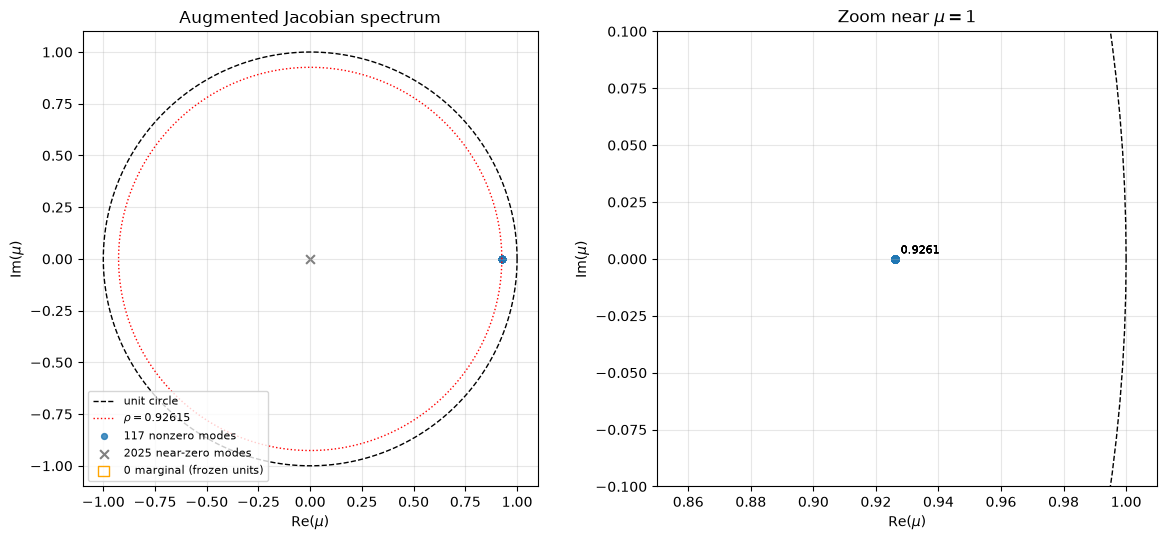

In [127]:

fig = plot_spectrum(mu, mu_full=mu)
# fig.savefig("spectrum.png", dpi=200)

### Plot timescales

c:\Users\Nishant Joshi\DDN_dynamics\DDN-public\timescale_utils.py:358: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax[1].set_xlim(np.log10(tau).min(), np.log10(tau).max())


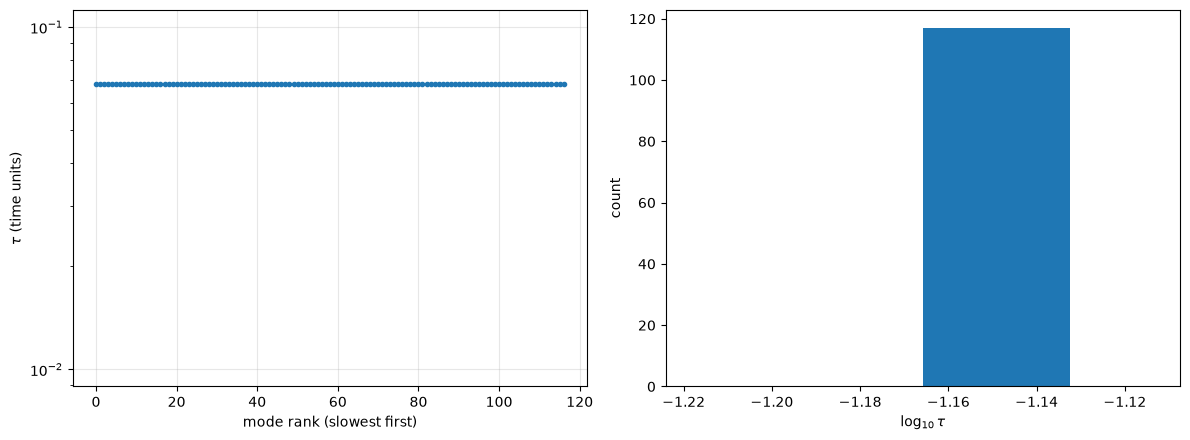

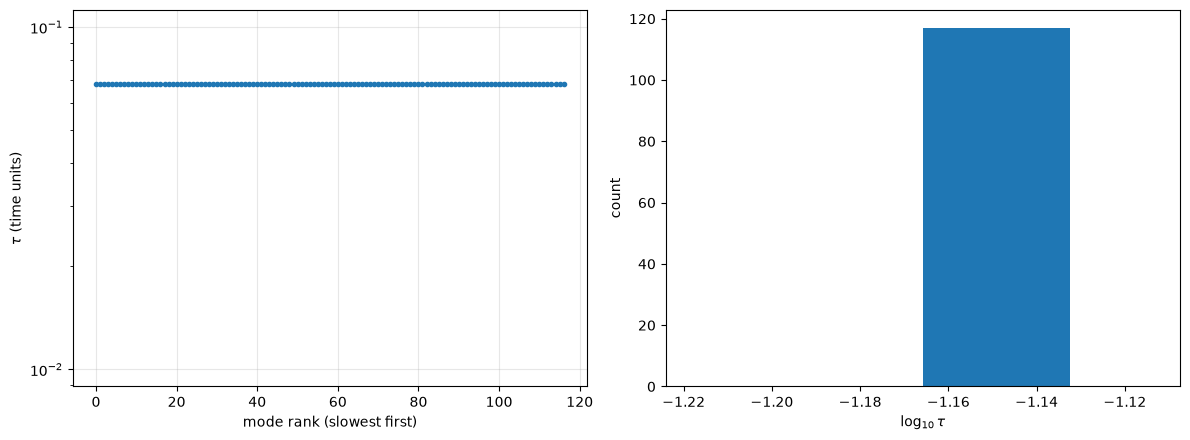

In [128]:

plot_tau(mu, net.dt)

In [129]:
alpha_a = np.asarray(alpha)[alpha > 0]
leak = np.sort(1 - alpha_a)
r = np.sort(np.abs(mu)); r = r[r > 1e-10]
m = np.array([np.min(np.abs(leak - x)) for x in r])
print("modes matching a leak value (1e-6):", np.sum(m < 1e-6), "of", len(r))
print("slowest:", r[-1], " nearest leak:", leak[np.argmin(np.abs(leak - r[-1]))])

modes matching a leak value (1e-6): 117 of 117
slowest: 0.9261456040692431  nearest leak: 0.9261456040692431


In [130]:
alpha_a = np.asarray(alpha)[alpha > 0]
act = alpha > 0

J0 = J_blocks_a[0]
diag_leak = np.diag(1 - alpha_a)

print("||J0 - diag(1-alpha)||_F :", np.linalg.norm(J0 - diag_leak))
for d, Jd in enumerate(J_blocks_a[1:], start=1):
    print(f"||J_{d}||_F:", np.linalg.norm(Jd))

for d, Wd in enumerate(W_by_delay):
    print(f"d={d} nnz(W_d)={np.count_nonzero(Wd)}  ||W_d||_F={np.linalg.norm(Wd):.3e}")

R = J0 - diag_leak
print("spectral radius of recurrent part:", np.max(np.abs(np.linalg.eigvals(R))))

||J0 - diag(1-alpha)||_F : 0.0
||J_1||_F: 0.0
||J_2||_F: 0.0
||J_3||_F: 0.0
||J_4||_F: 0.0
||J_5||_F: 0.0
||J_6||_F: 0.0
||J_7||_F: 0.0
||J_8||_F: 0.0
||J_9||_F: 0.0
||J_10||_F: 0.0
||J_11||_F: 0.0
||J_12||_F: 0.24731909449696365
||J_13||_F: 0.13595665653081068
||J_14||_F: 0.08989426952905605
||J_15||_F: 0.07676340095660428
||J_16||_F: 0.0776087154730106
||J_17||_F: 0.04138403442066681
d=0 nnz(W_d)=0  ||W_d||_F=0.000e+00
d=1 nnz(W_d)=2  ||W_d||_F=7.464e-01
d=2 nnz(W_d)=0  ||W_d||_F=0.000e+00
d=3 nnz(W_d)=0  ||W_d||_F=0.000e+00
d=4 nnz(W_d)=0  ||W_d||_F=0.000e+00
d=5 nnz(W_d)=0  ||W_d||_F=0.000e+00
d=6 nnz(W_d)=0  ||W_d||_F=0.000e+00
d=7 nnz(W_d)=0  ||W_d||_F=0.000e+00
d=8 nnz(W_d)=0  ||W_d||_F=0.000e+00
d=9 nnz(W_d)=0  ||W_d||_F=0.000e+00
d=10 nnz(W_d)=0  ||W_d||_F=0.000e+00
d=11 nnz(W_d)=0  ||W_d||_F=0.000e+00
d=12 nnz(W_d)=88  ||W_d||_F=4.663e+01
d=13 nnz(W_d)=18  ||W_d||_F=1.791e+01
d=14 nnz(W_d)=11  ||W_d||_F=1.687e+01
d=15 nnz(W_d)=12  ||W_d||_F=1.915e+01
d=16 nnz(W_d)=7  ||W_d||_

In [131]:

traj = run_zero_input(net, n_steps=20000, v_const=0.0,n_switch=10000)
x_final = traj[-1]



### activity dimension

In [132]:
ad_ddn_fixed_decay_net_wide = activity_dimension(traj[net.neurons_out, :10000-200])

### Plot trajectory 

(<Figure size 1600x450 with 3 Axes>,)

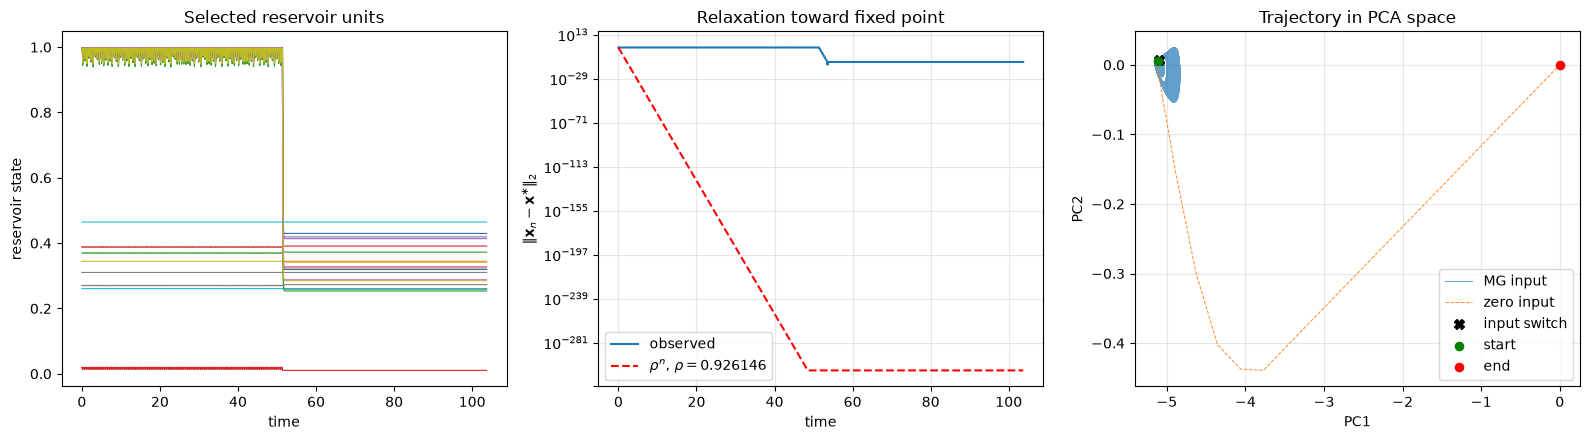

In [133]:
plot_relaxation(traj[net.neurons_out,:], x_star[net.neurons_out], rho=r_a.max(), dt=net.dt, n_units=20,switch_step=10000-200)

## DDN_dist_decay_net_wide

In [134]:
from reservoirpy.datasets import mackey_glass
net = best_nets_DDN_dist_decay_net_wide_dict
warmup  = 200

narma_input = mackey_glass(5000, seed=0)
INPUT = narma_input.T
sim = NetworkSimulator(net)
sim.warmup(narma_input[:warmup])

### Find fixedpoints 

In [135]:
state,_ = settle_to_fixed_point(net, input_constant=[0.0], max_steps=10000, tol=1e-9, consecutive_required=100)
x_star = state[net.neurons_out,0]

### Calculate Jacobian

In [136]:
alpha = net.decay[net.neurons_out]
W_by_delay = net.W_masked_list
active = np.asarray(alpha) > 0
alpha_a = np.asarray(alpha)[active]
x_a = x_star[active]
W_a = [Wd[np.ix_(active, active)] for Wd in W_by_delay]

J_blocks_a, g_a = delayed_esn_jacobian_blocks(W_a, alpha_a, x_a, activation='sigmoid')
J_aug_a = augmented_jacobian(J_blocks_a)
mu_a = np.linalg.eigvals(J_aug_a)
r_a = np.abs(mu_a)
print("spectral radius (active units):", r_a.max())

spectral radius (active units): 0.8330623161679646


In [137]:
dir_name = 'timescale_factors_MG/'
save_spectrum(mu_a, 'MG', 'DDN','dist','net_wide', dir_name)

In [138]:
mu = np.linalg.eigvals(J_aug_a)          # one matrix only
r = np.abs(mu)

print("rho:", r.max(), " -> tau_max:", -net.dt/np.log(r.max()))
print("top 10 |mu|:", np.sort(r)[-10:])

meaningful = (r > 1e-6) & (r < 1 - 1e-12)
tau = -net.dt/np.log(r[meaningful])
print("n meaningful:", meaningful.sum())
print("tau sorted (top 15):", np.sort(tau)[-15:])
print("tau quantiles:", np.quantile(tau, [0.1, 0.5, 0.9, 0.99]))

rho: 0.8330623161679646  -> tau_max: 0.02867735509303792
top 10 |mu|: [0.8330623  0.8330623  0.8330623  0.8330623  0.8330623  0.8330623
 0.8330623  0.8330623  0.8330623  0.83306232]
n meaningful: 1675
tau sorted (top 15): [0.02867735 0.02867735 0.02867735 0.02867735 0.02867735 0.02867735
 0.02867735 0.02867735 0.02867735 0.02867735 0.02867735 0.02867735
 0.02867735 0.02867735 0.02867736]
tau quantiles: [0.00045856 0.00068291 0.002001   0.02867735]


In [139]:
imag_tol = 1e-10
complex_mask = np.abs(mu.imag) > imag_tol

print("maximum |imaginary part|:", np.max(np.abs(mu.imag)))
print("complex modes, full spectrum:", complex_mask.sum())
print(
    "complex modes, retained spectrum:",
    np.count_nonzero(complex_mask & meaningful)
)

if np.any(complex_mask):
    complex_mu = mu[complex_mask]
    idx = np.argmax(np.abs(complex_mu))

    print("largest-magnitude complex eigenvalue:", complex_mu[idx])
    print("largest complex magnitude:", np.abs(complex_mu[idx]))

maximum |imaginary part|: 0.09836939252112124
complex modes, full spectrum: 1508
complex modes, retained spectrum: 1506
largest-magnitude complex eigenvalue: (0.8330623012228185+5.499992851497169e-10j)
largest complex magnitude: 0.8330623012228185


In [140]:
mu = np.asarray(mu)
mag = np.abs(mu)

imag_tol = 1e-10
complex_mask = np.abs(mu.imag) > imag_tol

if np.any(complex_mask):
    mu_complex = mu[complex_mask]
    j = np.argmax(np.abs(mu_complex))
    slowest_complex = mu_complex[j]

    r = np.abs(slowest_complex)
    theta = np.abs(np.angle(slowest_complex))

    print("slowest complex eigenvalue:", slowest_complex)
    print("largest complex magnitude:", r)

    if 0 < r < 1:
        tau_complex = -net.dt / np.log(r)
        period_complex = 2 * np.pi * net.dt / theta

        print("complex-mode decay time:", tau_complex)
        print("complex-mode oscillation period:", period_complex)
        print("decay time / period:", tau_complex / period_complex)
else:
    print("No complex eigenvalues above the chosen tolerance.")

slowest complex eigenvalue: (0.8330623012228185+5.499992851497169e-10j)
largest complex magnitude: 0.8330623012228185
complex-mode decay time: 0.02867735227627959
complex-mode oscillation period: 49847853.13242176
decay time / period: 5.752976402032333e-10


In [141]:
timescale_dict = timescales_from_eigenvalues(net,J_aug_a, zero_tol=1e-12)

rho: 0.8330623161679646  -> tau_max: 0.02867735509303792
top 10 |mu|: [0.8330623  0.8330623  0.8330623  0.8330623  0.8330623  0.8330623
 0.8330623  0.8330623  0.8330623  0.83306232]


### Plot spectral radius

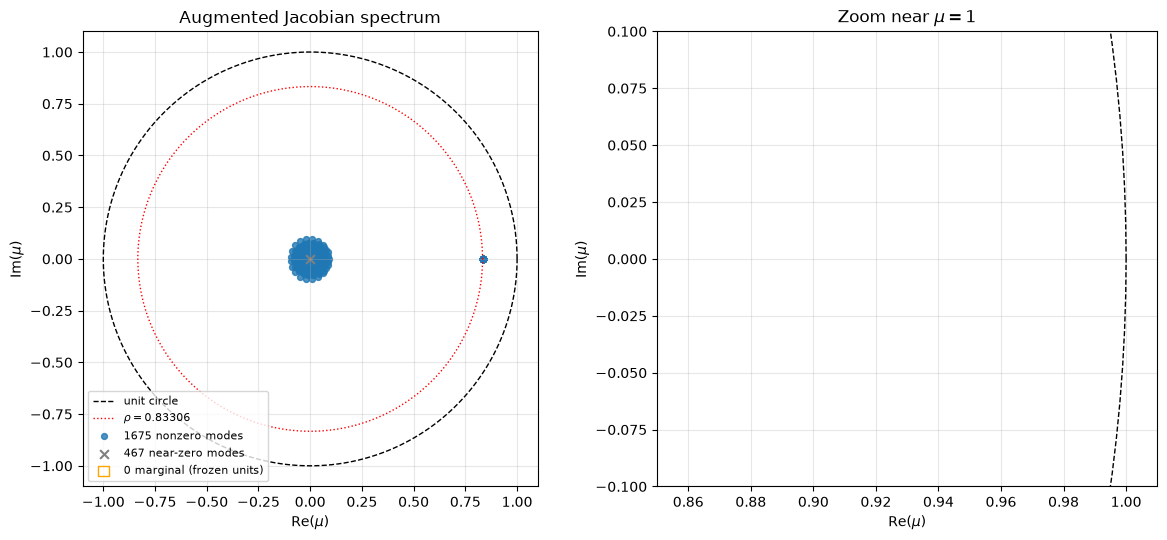

In [142]:

fig = plot_spectrum(mu, mu_full=mu)
# fig.savefig("spectrum.png", dpi=200)

### Plot timescales



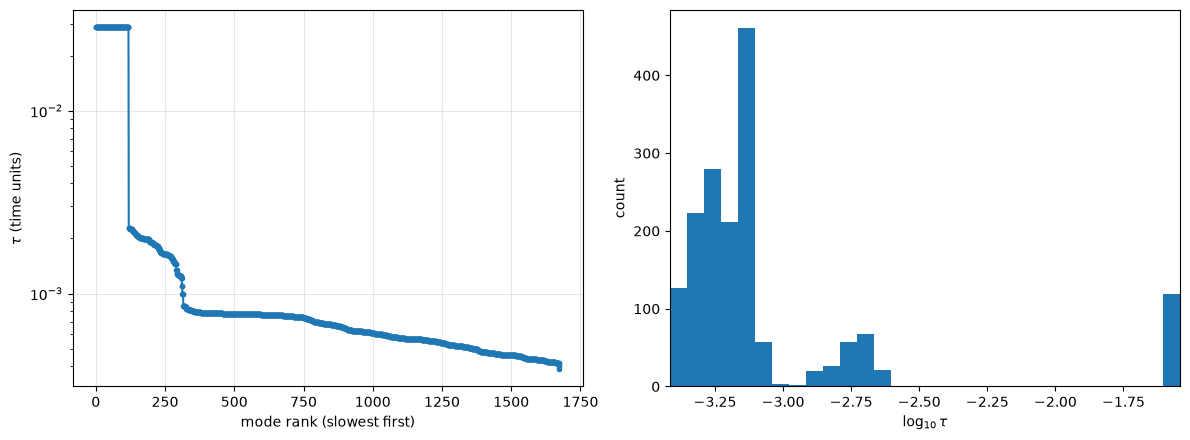

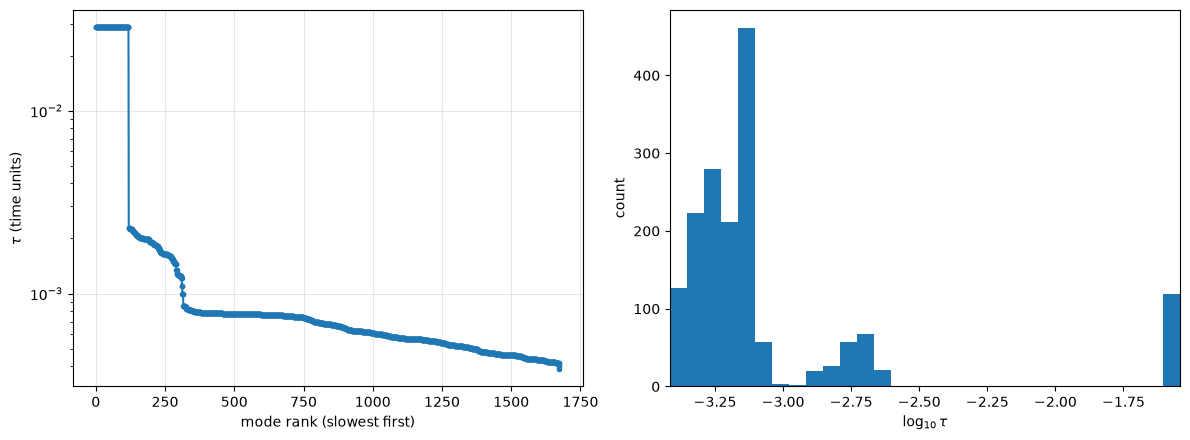

In [143]:

plot_tau(mu, net.dt)

In [144]:
alpha_a = np.asarray(alpha)[alpha > 0]
leak = np.sort(1 - alpha_a)
r = np.sort(np.abs(mu)); r = r[r > 1e-10]
m = np.array([np.min(np.abs(leak - x)) for x in r])
print("modes matching a leak value (1e-6):", np.sum(m < 1e-6), "of", len(r))
print("slowest:", r[-1], " nearest leak:", leak[np.argmin(np.abs(leak - r[-1]))])

modes matching a leak value (1e-6): 119 of 1679
slowest: 0.8330623161679646  nearest leak: 0.8330623012228169


In [145]:
alpha_a = np.asarray(alpha)[alpha > 0]
act = alpha > 0

J0 = J_blocks_a[0]
diag_leak = np.diag(1 - alpha_a)

print("||J0 - diag(1-alpha)||_F :", np.linalg.norm(J0 - diag_leak))
for d, Jd in enumerate(J_blocks_a[1:], start=1):
    print(f"||J_{d}||_F:", np.linalg.norm(Jd))

for d, Wd in enumerate(W_by_delay):
    print(f"d={d} nnz(W_d)={np.count_nonzero(Wd)}  ||W_d||_F={np.linalg.norm(Wd):.3e}")

R = J0 - diag_leak
print("spectral radius of recurrent part:", np.max(np.abs(np.linalg.eigvals(R))))

||J0 - diag(1-alpha)||_F : 0.0
||J_1||_F: 0.1449073047701121
||J_2||_F: 0.12422520540177265
||J_3||_F: 0.15088497742314308
||J_4||_F: 0.16714709081250137
||J_5||_F: 0.08692501925210548
||J_6||_F: 0.2007141408007629
||J_7||_F: 0.14667285112445805
||J_8||_F: 0.13614956767898734
||J_9||_F: 0.14359915866199752
||J_10||_F: 0.13231191994644587
||J_11||_F: 0.2003922067991507
||J_12||_F: 0.11658546871516418
||J_13||_F: 0.12056168768768136
||J_14||_F: 0.06961934908453857
||J_15||_F: 0.1441747787328541
||J_16||_F: 0.12395073670111276
||J_17||_F: 0.003497053644105554
d=0 nnz(W_d)=27  ||W_d||_F=3.095e+01
d=1 nnz(W_d)=76  ||W_d||_F=2.628e+01
d=2 nnz(W_d)=70  ||W_d||_F=2.557e+01
d=3 nnz(W_d)=95  ||W_d||_F=2.900e+01
d=4 nnz(W_d)=102  ||W_d||_F=3.224e+01
d=5 nnz(W_d)=68  ||W_d||_F=2.810e+01
d=6 nnz(W_d)=166  ||W_d||_F=3.921e+01
d=7 nnz(W_d)=86  ||W_d||_F=2.987e+01
d=8 nnz(W_d)=106  ||W_d||_F=3.129e+01
d=9 nnz(W_d)=96  ||W_d||_F=2.912e+01
d=10 nnz(W_d)=73  ||W_d||_F=2.739e+01
d=11 nnz(W_d)=156  ||W_d||

In [146]:

traj = run_zero_input(net, n_steps=20000, n_switch=10000, v_const=0.0)
x_final = traj[-1]


### activity dimension

In [147]:
ad_ddn_dist_decay_net_wide = activity_dimension(traj[net.neurons_out, :10000-200])

### plot trajectory

(<Figure size 1600x450 with 3 Axes>,)

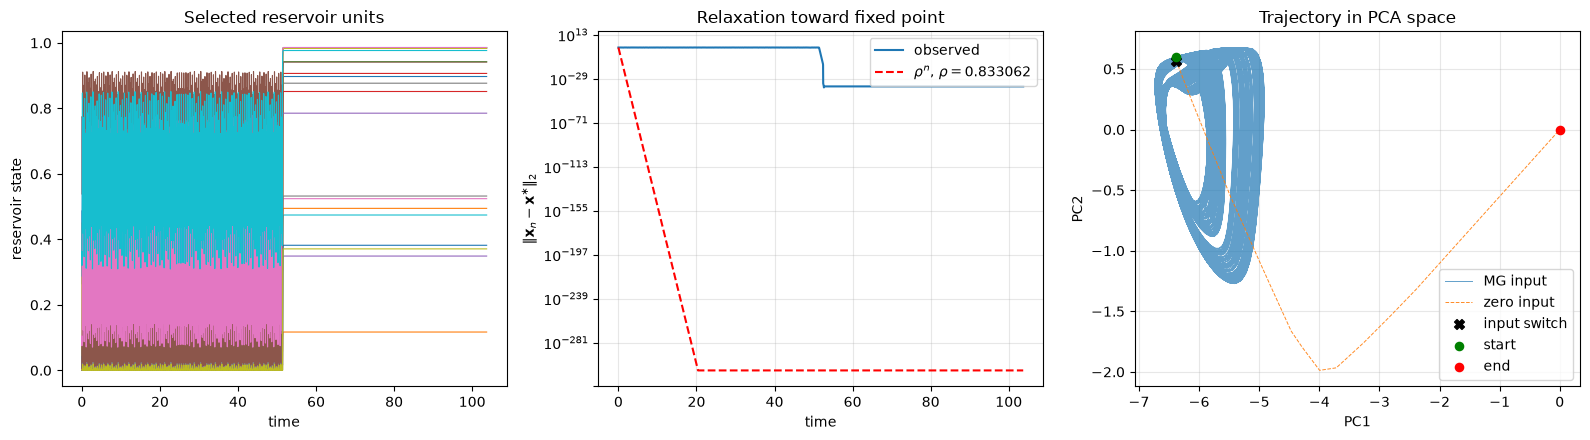

In [148]:
plot_relaxation(traj[net.neurons_out, :], x_star[net.neurons_out], rho=r_a.max(), dt=net.dt, n_units=20,switch_step=10000-200)

In [149]:
ad_name = ["esn_fixed_decay_net_wide", "esn_dist_decay_net_wide", "esn_fixed_decay_per_cluster", "esn_dist_decay_per_cluster",
            "ddn_fixed_decay_net_wide", "ddn_dist_decay_net_wide", "ddn_fixed_decay_per_cluster", "ddn_dist_decay_per_cluster"]
ad_vals = [ad_esn_fixed_decay_net_wide['participation_ratio'], 
           ad_esn_dist_decay_net_wide['participation_ratio'], 
           ad_esn_fixed_decay_per_cluster['participation_ratio'], 
           ad_esn_dist_decay_per_cluster['participation_ratio'], 
           ad_ddn_fixed_decay_net_wide['participation_ratio'],
           ad_ddn_dist_decay_net_wide['participation_ratio'],
           ad_ddn_fixed_decay_per_cluster['participation_ratio'],
           ad_ddn_dist_decay_per_cluster['participation_ratio']
           ]
    

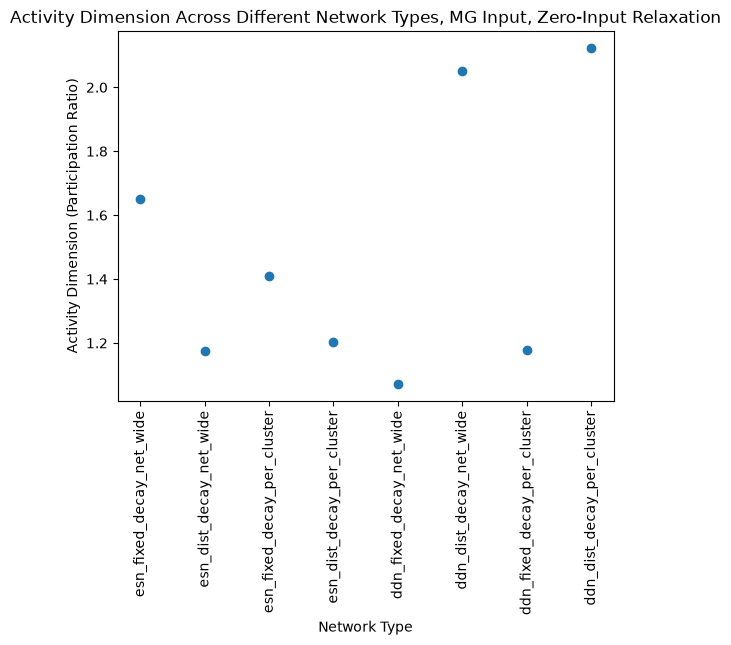

In [150]:
plt.plot(ad_name, ad_vals, "o")
plt.xticks(rotation=90) 
plt.xlabel("Network Type")
plt.ylabel("Activity Dimension (Participation Ratio)")
plt.title("Activity Dimension Across Different Network Types, MG Input, Zero-Input Relaxation")
plt.show()